# CPI Inflation Analysis

How fast did prices rise around the world between 2000 and 2023, and what goes along with high inflation?

This notebook combines the **UN Statistical Yearbook's consumer price indices** (general and food, about 200 countries, 2000–2021) with **World Bank indicators** (annual inflation, unemployment, GDP growth, GDP per head and income groups, 2000–2023).

1. Data and cleaning
2. How fast prices rose in each country
3. Food vs. general prices
4. Richer vs. poorer countries
5. Continents
6. Inflation over time, including COVID-19 and 2022
7. Inflation and the wider economy
8. Countries grouped by their price path
9. Forecasting
10. Pakistan and Southern Asia

The written findings are in [`FINDINGS.md`](FINDINGS.md). Charts are drawn with Matplotlib so they display on GitHub, and are saved to [`charts/`](charts).

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import geopandas as gpd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.2f}'.format)

# Chart styling
SURFACE, INK, INK_2, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']   # categorical, fixed order
BLUES = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#0d366b']    # sequential
NEUTRAL, NO_DATA = '#b9b8b2', '#ebeae6'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.major.size': 0, 'ytick.major.size': 0,
    'grid.color': GRID, 'legend.frameon': False,
})

CHARTS = Path('charts')
CHARTS.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(CHARTS / f'{name}.png', dpi=150, bbox_inches='tight')

def short(name):
    return name.split(' (')[0]

## 1. Data and cleaning

### 1.1 Country metadata

ISO and UN M49 codes, continents and UN regions for every country (from the [Datahub country-codes](https://github.com/datasets/country-codes) dataset), plus World Bank income groups.

In [2]:
codes = pd.read_csv('data/country_codes.csv', dtype=str, keep_default_na=False)
codes['m49'] = codes['m49'].astype(int)
CONTINENTS = {'AF': 'Africa', 'AS': 'Asia', 'EU': 'Europe', 'NA': 'North America', 'SA': 'South America', 'OC': 'Oceania'}
codes['continent'] = codes['continent_code'].map(CONTINENTS)

income = pd.read_csv('data/wb_income_groups.csv')
INCOME_NAMES = {'LIC': 'Low income', 'LMC': 'Lower-middle income', 'UMC': 'Upper-middle income', 'HIC': 'High income'}
income['income_group'] = income['income_group'].map(INCOME_NAMES)

meta = codes.merge(income[['iso3', 'income_group']], on='iso3', how='left').set_index('iso3')
print(f'{len(meta)} countries and territories; {meta.income_group.notna().sum()} with a World Bank income group')

249 countries and territories; 215 with a World Bank income group


### 1.2 UN consumer price indices

General and food price indices from the UN Statistical Yearbook (SYB65, September 2022). The file's footnotes matter for any calculation:

- **Unit changes.** Six values are given *"in millions"* or *"in billions"* (Venezuela's hyperinflation years). Read as plain numbers, they make prices look like they fell, so they are scaled back up.
- **Placeholder zeros.** Two values (Ethiopia and Maldives, 2005) are recorded as 0, which isn't a valid price index. They are treated as missing.
- **Index-base changes.** Most series use 2010 = 100, but some switch base partway through (for example *"Base: 2018=100"*). Each series is split into **segments** that share a base, and price changes are only ever measured *within* a segment.

In [3]:
GENERAL, FOOD = 'Consumer price index: General', 'Consumer price index: Food'

df = pd.read_csv('data/un_cpi_syb65.csv').rename(columns={'Area Code': 'm49'})
df['Value'] = pd.to_numeric(df['Value'].astype(str).str.replace(',', ''), errors='coerce')
df['Series'] = df['Series'].map({GENERAL: 'General', FOOD: 'Food'})

def index_base(note):
    # 'Index base: 2015=100.', 'Base: April 2019 = 100', 'Base 2015 - 2016 = 100' ...
    if isinstance(note, str):
        m = re.search(r'(?:index base|base)\s*:?\s*([^;=]+?)\s*=\s*100', note, re.I)
        if m:
            return m.group(1).strip()
    return '2010'

def unit_scale(note):
    if isinstance(note, str):
        if 'Figures in billions' in note: return 1e9
        if 'Figures in millions' in note: return 1e6
    return 1.0

df['base'] = df['Footnotes'].apply(index_base)
df['scale'] = df['Footnotes'].apply(unit_scale)
df['Value'] = df['Value'] * df['scale']
n_zero = (df.Value <= 0).sum()
df.loc[df.Value <= 0, 'Value'] = np.nan
df = df.sort_values(['Country', 'Series', 'Year']).reset_index(drop=True)
df['segment'] = df.groupby(['Country', 'Series'])['base'].transform(lambda b: (b != b.shift()).cumsum())
df = df.merge(codes[['m49', 'iso3', 'continent']], on='m49', how='left')
NAMES = df.dropna(subset=['iso3']).drop_duplicates('iso3').set_index('iso3')['Country']   # display names

n_series = df.groupby(['Country', 'Series']).ngroups
n_rebased = (df.groupby(['Country', 'Series'])['segment'].max() > 1).sum()
print(f'{len(df):,} rows · {df.Country.nunique()} countries and areas · years {sorted(df.Year.unique())}')
print(f'{n_rebased} of {n_series} series change index base partway through')
print(f'{(df.scale > 1).sum()} values rescaled from "millions"/"billions"; {n_zero} zero values treated as missing')

2,049 rows · 202 countries and areas · years [np.int64(2000), np.int64(2005), np.int64(2010), np.int64(2015), np.int64(2019), np.int64(2020), np.int64(2021)]
35 of 386 series change index base partway through
6 values rescaled from "millions"/"billions"; 2 zero values treated as missing


### 1.3 World Bank indicators

Downloaded from the World Bank API (last updated 11 November 2026) for 2000–2023:

| Indicator | Code |
| --- | --- |
| Inflation, consumer prices (annual %) | `FP.CPI.TOTL.ZG` |
| Unemployment, % of labour force (ILO modelled estimate) | `SL.UEM.TOTL.ZS` |
| GDP growth (annual %, constant prices) | `NY.GDP.MKTP.KD.ZG` |
| GDP per head (current US$) | `NY.GDP.PCAP.CD` |

In [4]:
def load_wb(name, column):
    wide = pd.read_csv(f'data/wb_{name}.csv')
    long = wide.melt(id_vars='iso3', var_name='year', value_name=column).dropna()
    long['year'] = long['year'].astype(int)
    return long

wb = load_wb('inflation', 'inflation')
for name, column in [('unemployment', 'unemployment'), ('gdp_growth', 'gdp_growth'), ('gdp_per_capita', 'gdp_per_capita')]:
    wb = wb.merge(load_wb(name, column), on=['iso3', 'year'], how='outer')
wb = wb.merge(meta[['continent', 'un_subregion', 'income_group']], left_on='iso3', right_index=True, how='left')

for column in ['inflation', 'unemployment', 'gdp_growth', 'gdp_per_capita']:
    have = wb.dropna(subset=[column])
    print(f'{column:15s} {have.iso3.nunique()} countries, {len(have):,} country-years')

inflation       193 countries, 4,352 country-years
unemployment    187 countries, 4,484 country-years
gdp_growth      214 countries, 4,968 country-years
gdp_per_capita  214 countries, 5,042 country-years


## 2. How fast prices rose in each country

Each country gets an **average annual inflation rate** from the UN index: the compound rate that turns the starting index into the ending one.

$$r = \left(\frac{CPI_{\text{end}}}{CPI_{\text{start}}}\right)^{1/(\text{end} - \text{start})} - 1$$

It is measured over the longest same-base segment covering at least five years, usually 2000–2021. Unlike a total change over the period, it is comparable between countries with different date ranges.

In [5]:
def growth(s):
    # Compound annual growth between the first and last points of a sorted series
    y0, y1 = s.index[0], s.index[-1]
    return (s.iloc[-1] / s.iloc[0]) ** (1 / (y1 - y0)) - 1

def longest_segment_rate(d, min_years=5):
    best = None
    for _, seg in d.groupby('segment'):
        s = seg.dropna(subset=['Value']).set_index('Year')['Value']
        if len(s) >= 2 and s.index[-1] - s.index[0] >= min_years:
            span = s.index[-1] - s.index[0]
            if best is None or span > best[2] or (span == best[2] and s.index[-1] > best[1]):
                best = (s.index[0], s.index[-1], span, growth(s) * 100)
    return best

def window_rate(d, y0, y1):
    # Average annual change between two years, only within one same-base segment
    for _, seg in d.groupby('segment'):
        s = seg.dropna(subset=['Value']).set_index('Year')['Value']
        if y0 in s.index and y1 in s.index:
            return ((s[y1] / s[y0]) ** (1 / (y1 - y0)) - 1) * 100
    return np.nan

rows = []
for (country, series), d in df.groupby(['Country', 'Series']):
    r = longest_segment_rate(d)
    if r:
        rows.append(dict(Country=country, Series=series, iso3=d.iso3.iloc[0], continent=d.continent.iloc[0],
                         start=r[0], end=r[1], annual_rate=r[3]))
rates = pd.DataFrame(rows)
general = rates[rates.Series == 'General'].set_index('Country')
food = rates[rates.Series == 'Food'].set_index('Country')
general['income_group'] = general.iso3.map(meta.income_group)

print(f'General: {len(general)} countries, median {general.annual_rate.median():.1f}% a year')
print(f'Food:    {len(food)} countries, median {food.annual_rate.median():.1f}% a year')
cols = ['continent', 'start', 'end', 'annual_rate']
display(general.sort_values('annual_rate', ascending=False)[cols].head(10).rename(columns={'annual_rate': '% a year'}))
display(general.sort_values('annual_rate')[cols].head(10).rename(columns={'annual_rate': '% a year'}))

General: 194 countries, median 3.1% a year
Food:    156 countries, median 3.6% a year


,continent,start,end,% a year
Country,,,,
Venezuela (Boliv. Rep. of),South America,2010,2021,694.91
South Sudan,Africa,2010,2021,63.67
Zimbabwe,Africa,2010,2021,43.74
Sudan,Africa,2000,2021,34.78
Angola,Africa,2000,2019,29.23
Syrian Arab Republic,Asia,2010,2019,27.59
Iran (Islamic Republic of),Asia,2015,2021,23.71
Dem. Rep. of the Congo,Africa,2000,2015,21.75
Belarus,Europe,2000,2021,18.71


,continent,start,end,% a year
Country,,,,
Kiribati,Oceania,2010,2019,0.06
Japan,Asia,2000,2021,0.11
Libya,Africa,2000,2010,0.12
Brunei Darussalam,Asia,2000,2021,0.37
Saint Kitts and Nevis,North America,2010,2021,0.37
Switzerland,Europe,2000,2021,0.38
Réunion,Africa,2010,2020,0.74
French Guiana,South America,2010,2020,0.81
New Caledonia,Oceania,2010,2021,0.90


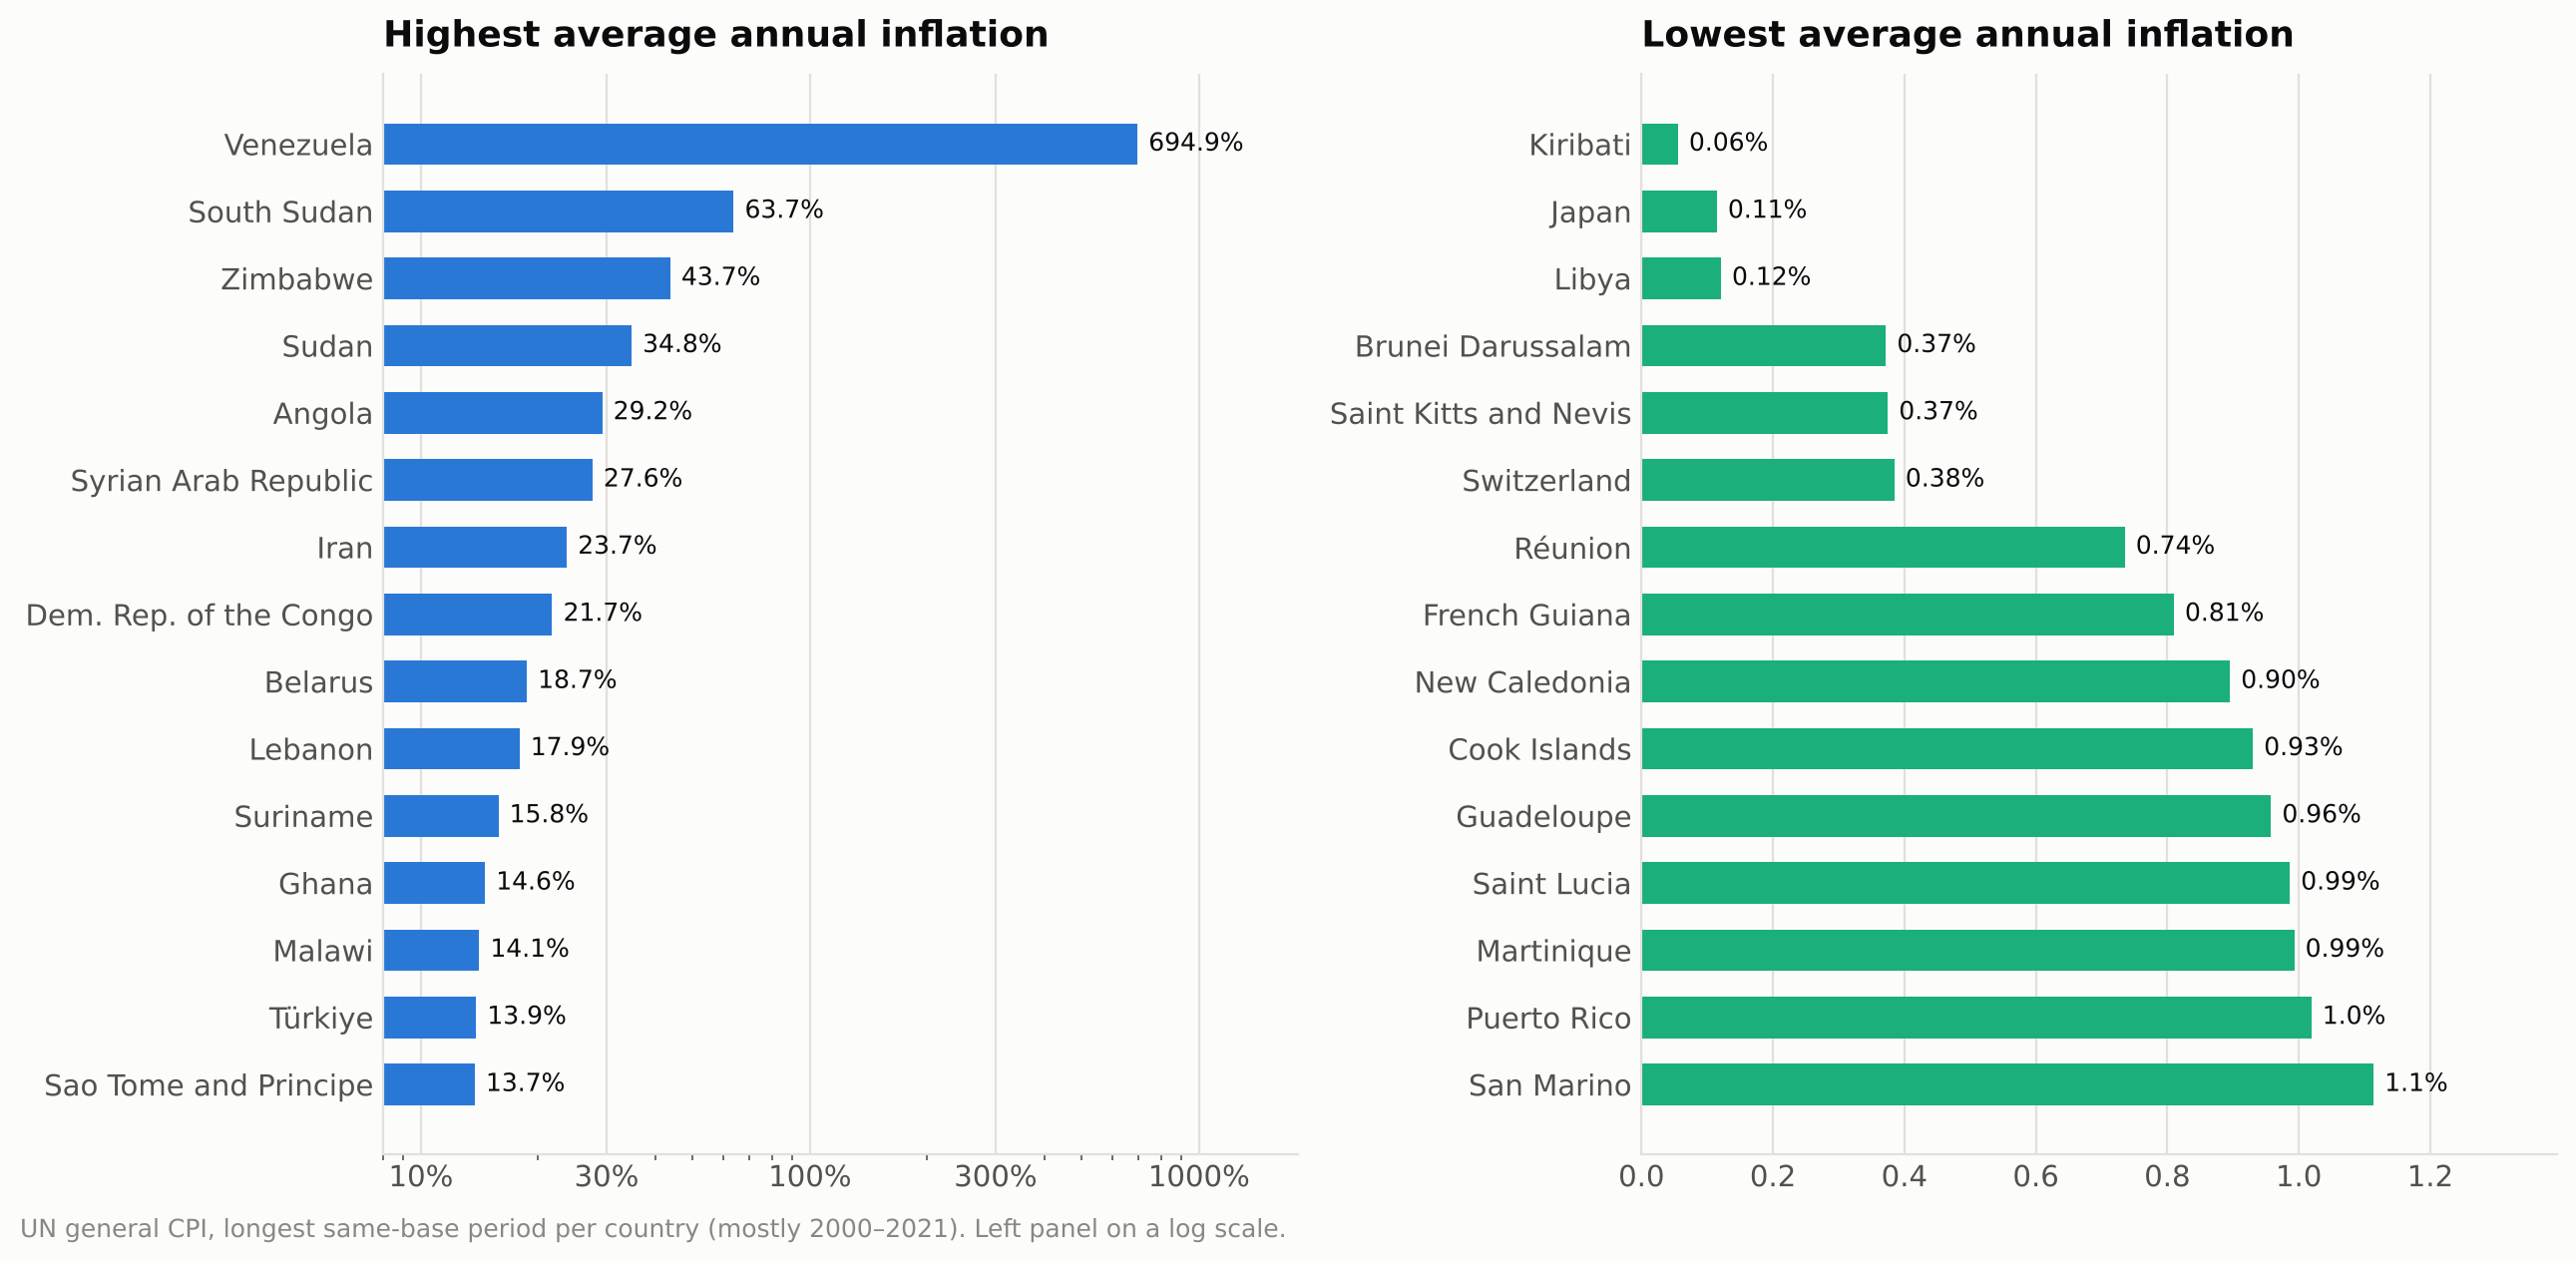

In [6]:
top = general.annual_rate.sort_values(ascending=False).head(15)
low = general.annual_rate.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, data, title, log in [(axes[0], top, 'Highest', True), (axes[1], low, 'Lowest', False)]:
    y = np.arange(len(data))
    ax.barh(y, data.values, height=0.62, color=SERIES[0] if log else SERIES[2])
    ax.set_yticks(y, [short(c) for c in data.index])
    ax.invert_yaxis()
    for yi, v in zip(y, data.values):
        ax.annotate(f'{v:.1f}%' if v >= 1 else f'{v:.2f}%', (v, yi), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=9, color=INK)
    if log:
        ax.set_xscale('log')
        ax.set_xticks([10, 30, 100, 300, 1000], ['10%', '30%', '100%', '300%', '1000%'])
        ax.set_xlim(8, 1800)
    else:
        ax.set_xlim(0, data.max() * 1.25)
    ax.grid(axis='x'); ax.set_axisbelow(True)
    ax.set_title(f'{title} average annual inflation', pad=10)
fig.text(0.01, -0.01, 'UN general CPI, longest same-base period per country (mostly 2000–2021). Left panel on a log scale.',
         color=MUTED, fontsize=9)
fig.tight_layout()
save(fig, 'top-bottom')
plt.show()

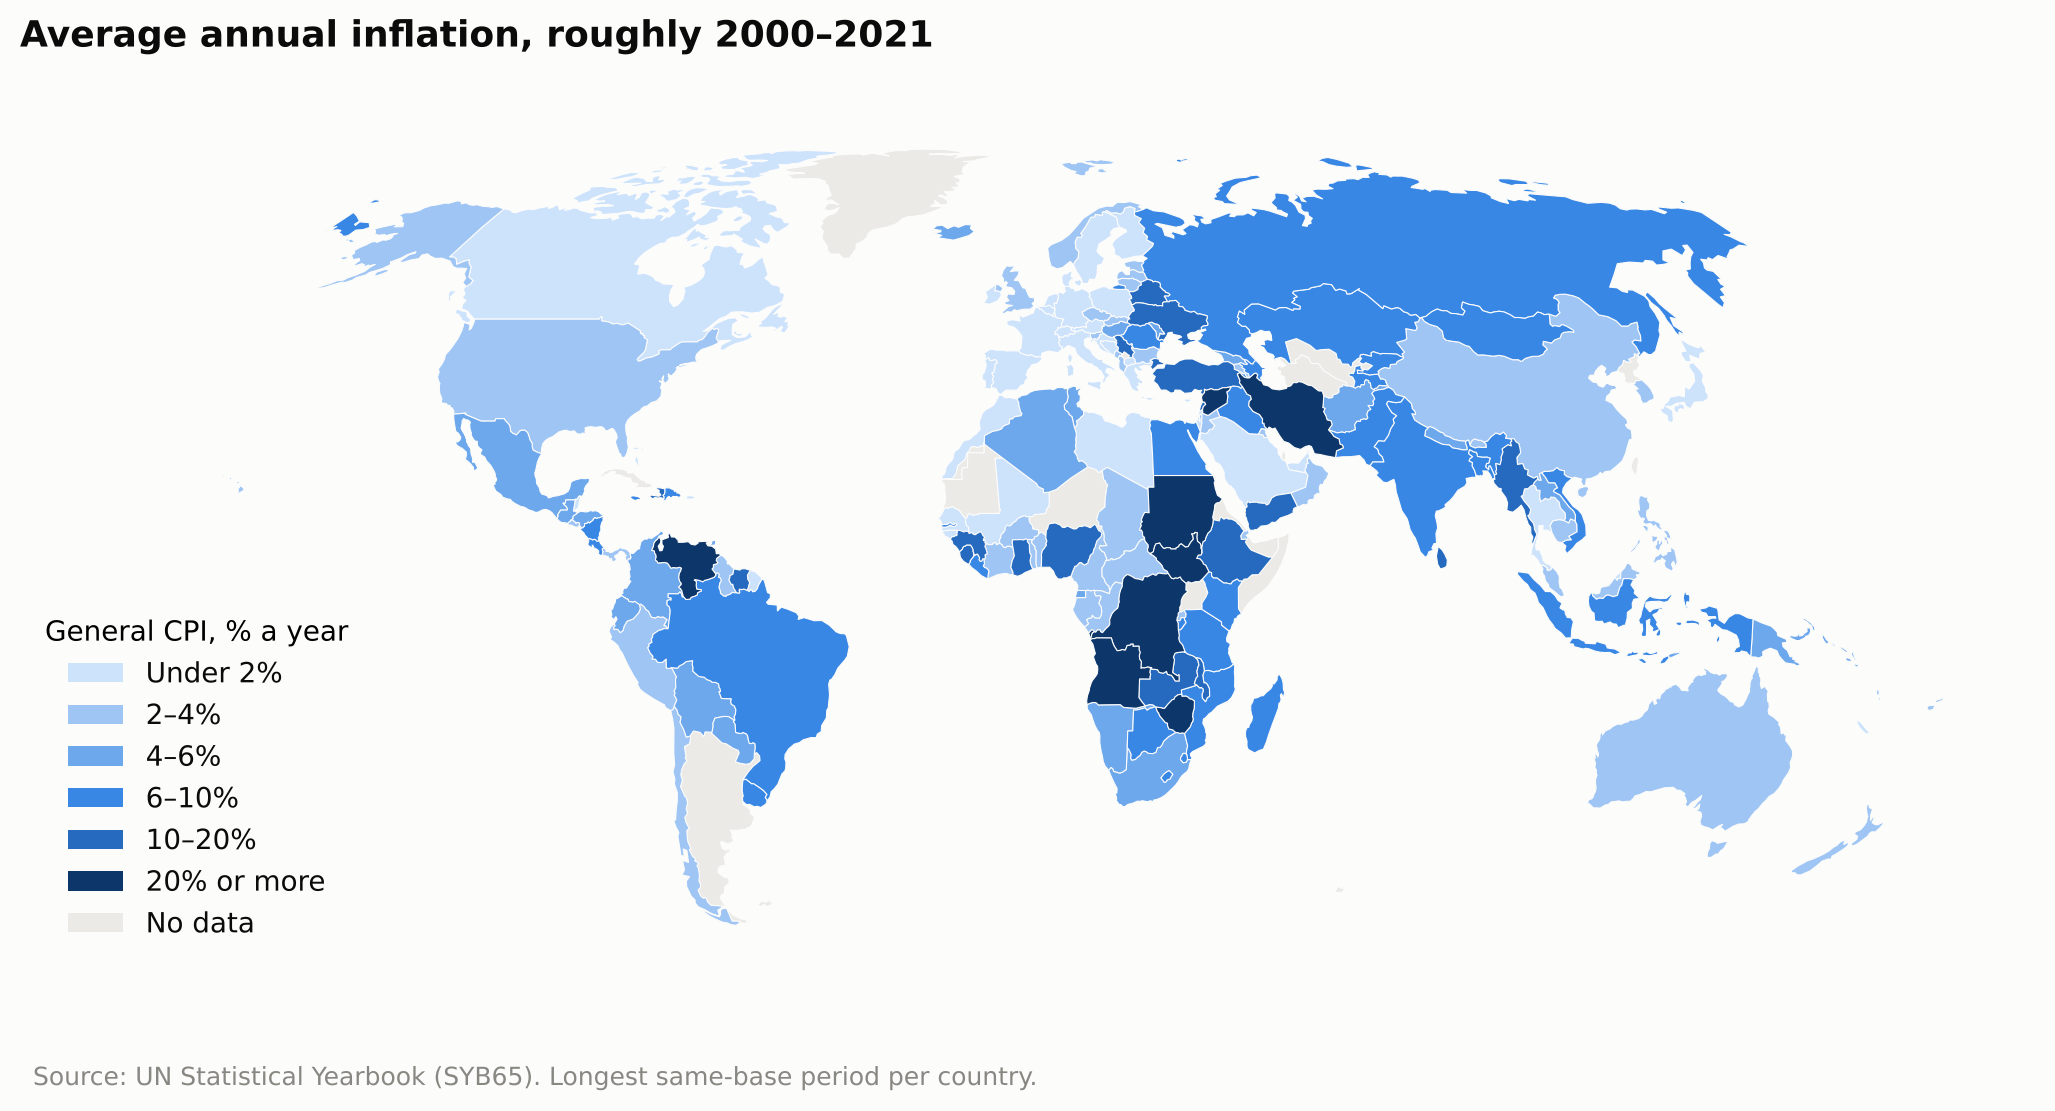

Shown on the map: 157 of 194 countries (small islands are too small to draw)


In [7]:
world = gpd.read_file('data/naturalearth_lowres/naturalearth_lowres.shp')
world.loc[world.name == 'France', 'iso_a3'] = 'FRA'      # known gaps in this Natural Earth release
world.loc[world.name == 'Norway', 'iso_a3'] = 'NOR'
world = world[world.name != 'Antarctica'].to_crs('+proj=robin')

bins = [-np.inf, 2, 4, 6, 10, 20, np.inf]
labels = ['Under 2%', '2–4%', '4–6%', '6–10%', '10–20%', '20% or more']
general['band'] = pd.cut(general.annual_rate, bins=bins, labels=labels, right=False)
mapped = world.merge(general[['iso3', 'band']], left_on='iso_a3', right_on='iso3', how='left')

fig, ax = plt.subplots(figsize=(13, 6.6))
mapped[mapped.band.isna()].plot(ax=ax, color=NO_DATA, edgecolor=SURFACE, linewidth=0.4)
for label, color in zip(labels, BLUES):
    part = mapped[mapped.band == label]
    if len(part):
        part.plot(ax=ax, color=color, edgecolor=SURFACE, linewidth=0.4)
ax.set_axis_off()
ax.set_title('Average annual inflation, roughly 2000–2021', pad=12)
handles = [Patch(facecolor=c, label=l) for l, c in zip(labels, BLUES)] + [Patch(facecolor=NO_DATA, label='No data')]
ax.legend(handles=handles, loc='lower left', title='General CPI, % a year', fontsize=10, title_fontsize=10, labelcolor=INK)
fig.text(0.13, 0.08, 'Source: UN Statistical Yearbook (SYB65). Longest same-base period per country.', color=MUTED, fontsize=9)
save(fig, 'world-map')
plt.show()
print(f'Shown on the map: {mapped.band.notna().sum()} of {len(general)} countries (small islands are too small to draw)')

## 3. Food vs. general prices

Food and general price series often cover different years: food data frequently starts in 2010, general in 2000. To compare them fairly, both are measured over exactly the same years, within same-base segments, for every country that has both.

156 countries compared over matching years
Food inflation higher in 123 of them (79%)
Median gap (food minus general): +0.64 percentage points a year


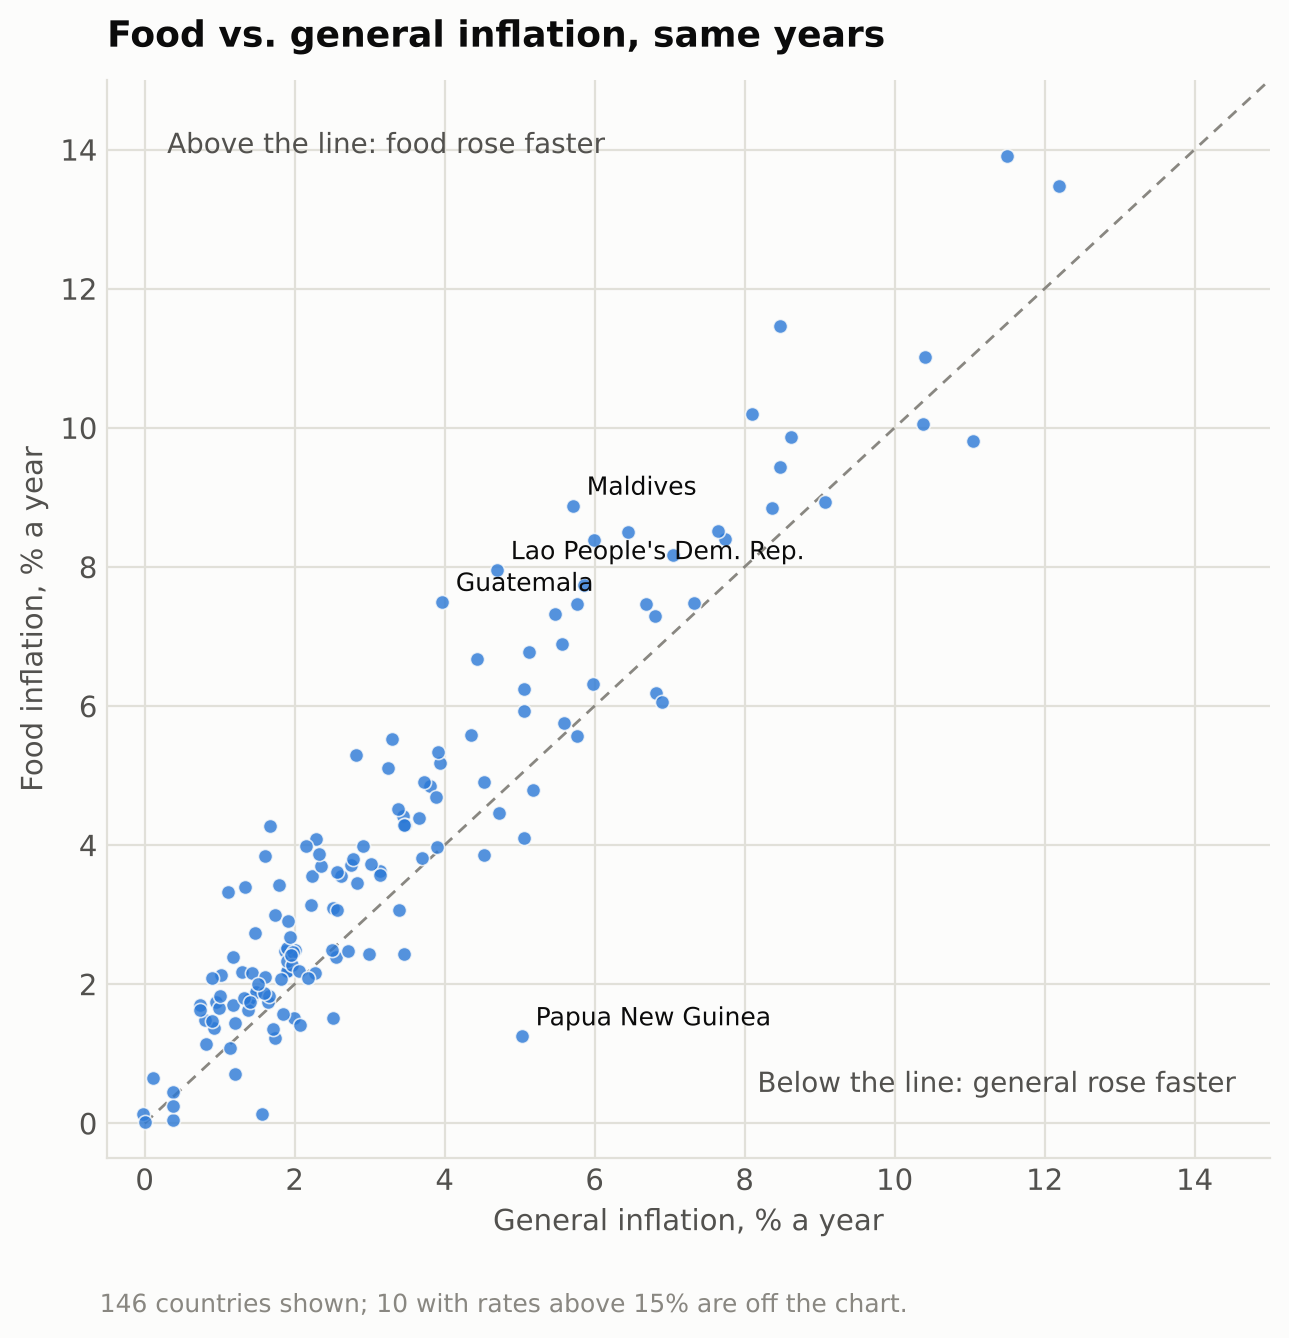

In [8]:
def common_window_rates(country, min_years=5):
    best = None
    g = df[(df.Country == country) & (df.Series == 'General')].dropna(subset=['Value'])
    f = df[(df.Country == country) & (df.Series == 'Food')].dropna(subset=['Value'])
    for _, gs in g.groupby('segment'):
        for _, fs in f.groupby('segment'):
            years = sorted(set(gs.Year) & set(fs.Year))
            if len(years) >= 2 and years[-1] - years[0] >= min_years:
                span = years[-1] - years[0]
                if best is None or span > best[0]:
                    gv, fv = gs.set_index('Year').Value, fs.set_index('Year').Value
                    best = (span, years[0], years[-1], growth(gv.loc[years]) * 100, growth(fv.loc[years]) * 100)
    return best

pairs = []
for c in sorted(set(general.index) & set(food.index)):
    r = common_window_rates(c)
    if r:
        pairs.append(dict(Country=c, start=r[1], end=r[2], general=r[3], food=r[4]))
pairs = pd.DataFrame(pairs).set_index('Country')
pairs['gap'] = pairs.food - pairs.general

print(f'{len(pairs)} countries compared over matching years')
print(f'Food inflation higher in {(pairs.gap > 0).sum()} of them ({(pairs.gap > 0).mean():.0%})')
print(f'Median gap (food minus general): {pairs.gap.median():+.2f} percentage points a year')

lim = 15
inside = pairs[(pairs.general <= lim) & (pairs.food <= lim)]
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
ax.scatter(inside.general, inside.food, s=26, color=SERIES[0], alpha=0.8, linewidths=0.6, edgecolors=SURFACE, zorder=3)
ax.text(0.3, lim * 0.93, 'Above the line: food rose faster', ha='left', color=INK_2, fontsize=10)
ax.text(lim * 0.97, lim * 0.03, 'Below the line: general rose faster', ha='right', color=INK_2, fontsize=10)
for c in inside.gap.abs().sort_values(ascending=False).index[:4]:
    ax.annotate(short(c), (inside.general[c], inside.food[c]), xytext=(5, 4), textcoords='offset points', fontsize=9, color=INK)
ax.set_xlim(-0.5, lim); ax.set_ylim(-0.5, lim)
ax.set_xlabel('General inflation, % a year'); ax.set_ylabel('Food inflation, % a year')
ax.grid(True); ax.set_axisbelow(True)
ax.set_title('Food vs. general inflation, same years', pad=12)
fig.text(0.12, 0.0, f'{len(inside)} countries shown; {len(pairs) - len(inside)} with rates above {lim}% are off the chart.',
         color=MUTED, fontsize=9)
save(fig, 'food-vs-general')
plt.show()

## 4. Richer vs. poorer countries

Two ways to compare: the World Bank's **income groups**, and each country's **GDP per head** (median over 2000–2021, in current US dollars).

In [9]:
ORDER = ['Low income', 'Lower-middle income', 'Upper-middle income', 'High income']
by_income = general.dropna(subset=['income_group'])
display(by_income.groupby('income_group').annual_rate.agg(countries='count', median='median', mean='mean')
        .reindex(ORDER).rename(columns={'median': 'median % a year', 'mean': 'mean % a year'}))

rich = by_income.income_group == 'High income'
print(f"High income: median {by_income[rich].annual_rate.median():.1f}% a year · "
      f"all other groups: median {by_income[~rich].annual_rate.median():.1f}% a year")

gdp_pc = wb[(wb.year >= 2000) & (wb.year <= 2021)].groupby('iso3').gdp_per_capita.median()
general['gdp_per_capita'] = general.iso3.map(gdp_pc)
both = general.dropna(subset=['gdp_per_capita'])
rho, p = spearmanr(both.gdp_per_capita, both.annual_rate)
print(f'{len(both)} countries: Spearman correlation between GDP per head and inflation = {rho:.2f} (p = {p:.1g})')

,countries,median % a year,mean % a year
income_group,,,
Low income,20,8.56,12.88
Lower-middle income,45,5.97,23.02
Upper-middle income,53,4.33,5.51
High income,68,1.93,2.43


High income: median 1.9% a year · all other groups: median 5.5% a year
186 countries: Spearman correlation between GDP per head and inflation = -0.60 (p = 1e-19)


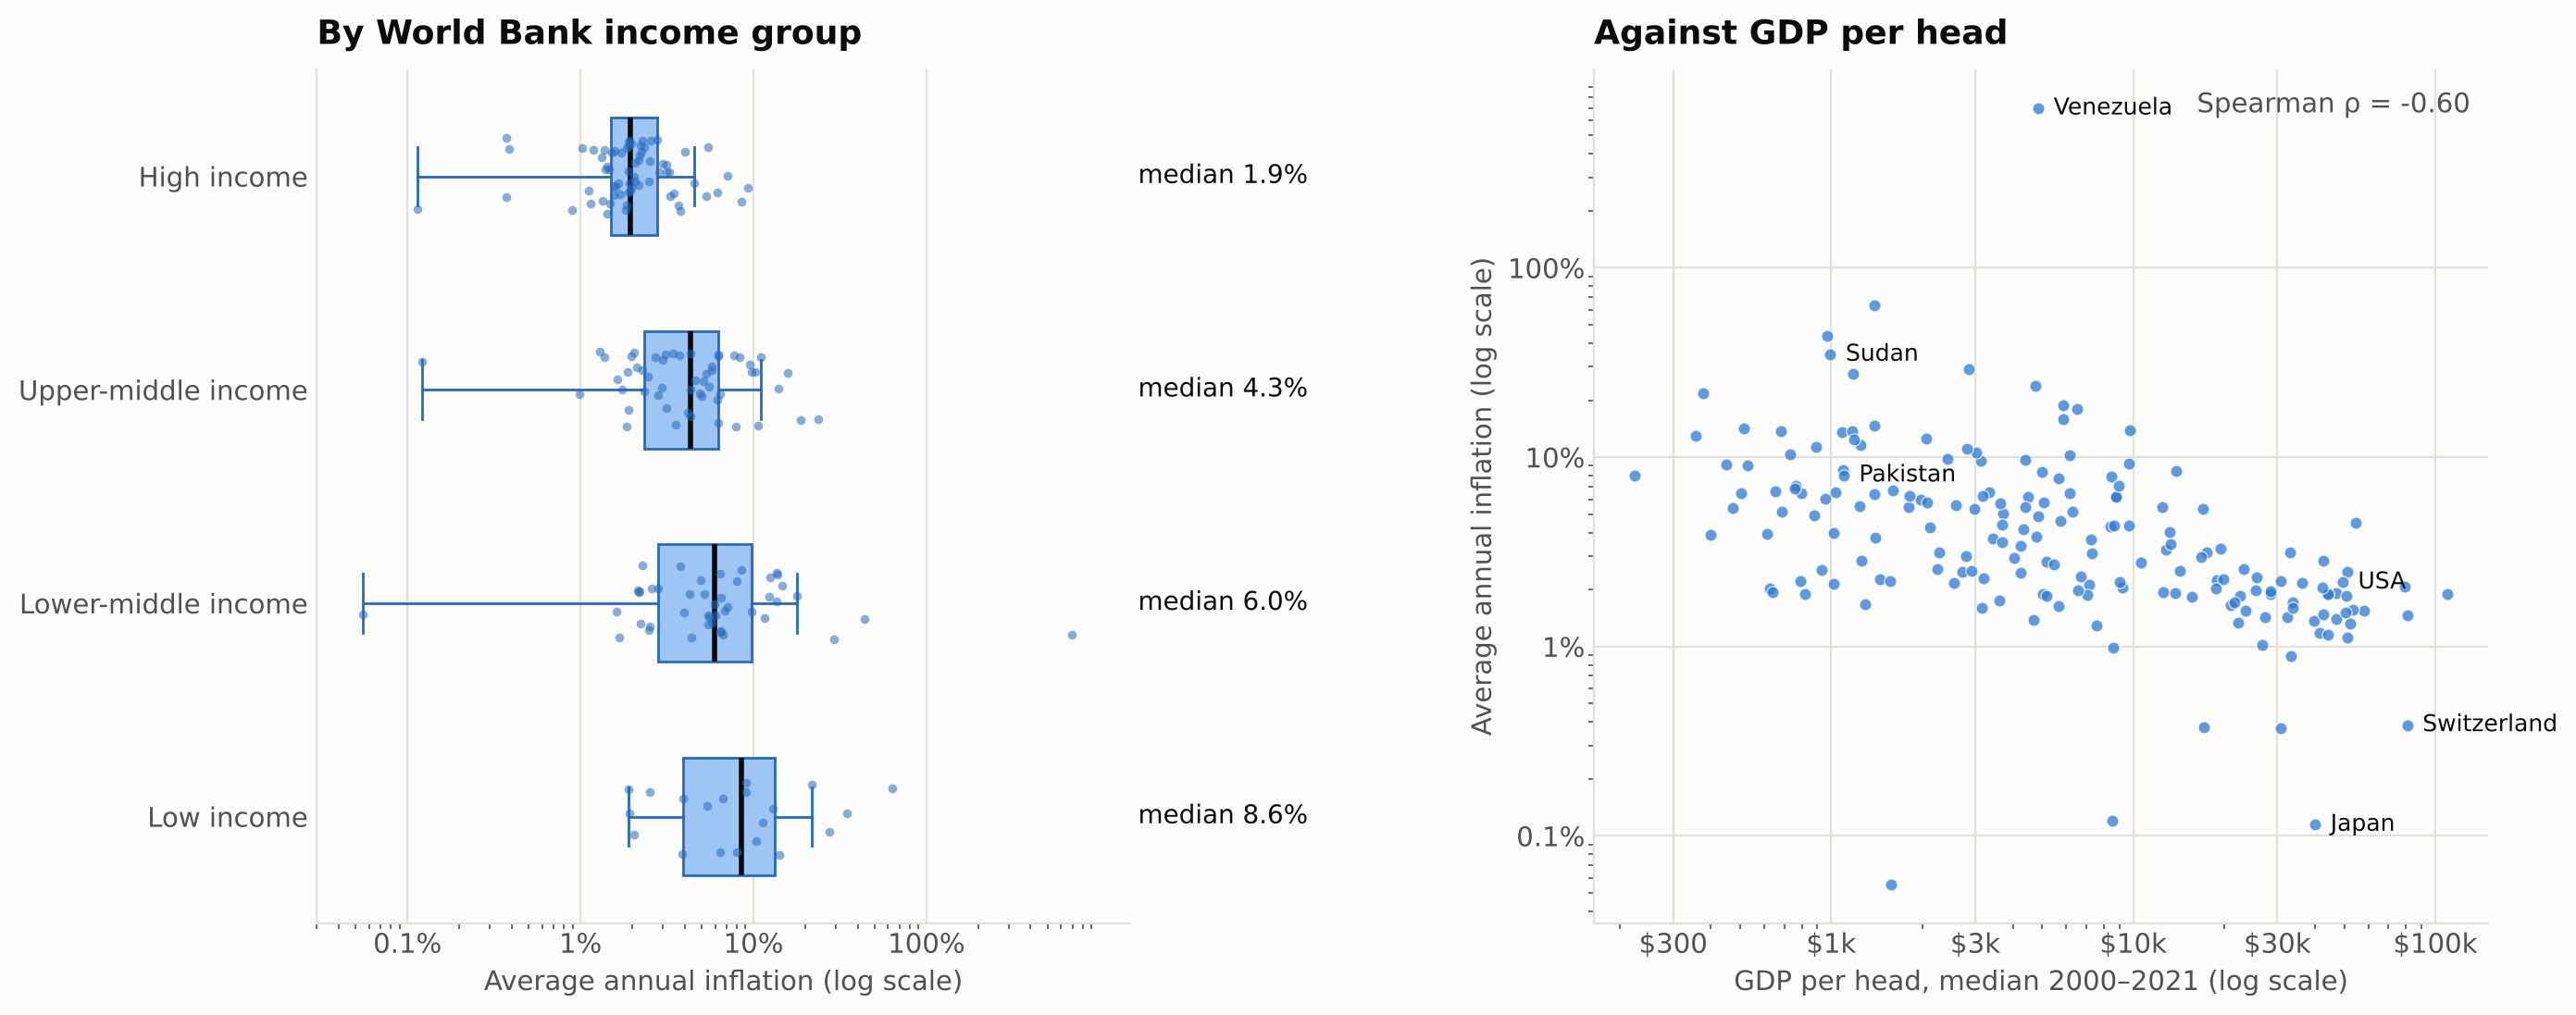

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'width_ratios': [1, 1.1]})

data = [by_income.loc[by_income.income_group == g, 'annual_rate'].clip(lower=0.05) for g in ORDER]
ax1.boxplot(data, orientation='horizontal', widths=0.55, patch_artist=True, showfliers=False,
            medianprops=dict(color=INK, linewidth=2),
            boxprops=dict(facecolor=BLUES[1], edgecolor=BLUES[4]), whiskerprops=dict(color=BLUES[4]), capprops=dict(color=BLUES[4]))
rng = np.random.default_rng(0)
for i, d in enumerate(data, start=1):
    ax1.scatter(d, i + rng.uniform(-0.18, 0.18, len(d)), s=12, color=BLUES[4], alpha=0.55, zorder=3, linewidths=0)
    ax1.annotate(f'median {d.median():.1f}%', (1.01, i), xycoords=('axes fraction', 'data'), va='center', fontsize=10, color=INK)
ax1.set_yticks(range(1, 5), ORDER)
ax1.set_xscale('log')
ax1.set_xticks([0.1, 1, 10, 100], ['0.1%', '1%', '10%', '100%'])
ax1.set_xlim(0.03, 1500)
ax1.grid(axis='x'); ax1.set_axisbelow(True)
ax1.set_xlabel('Average annual inflation (log scale)')
ax1.set_title('By World Bank income group', pad=10)

ax2.scatter(both.gdp_per_capita, both.annual_rate.clip(lower=0.05), s=22, color=SERIES[0], alpha=0.75,
            edgecolors=SURFACE, linewidths=0.5)
ax2.set_xscale('log'); ax2.set_yscale('log')
ax2.set_xticks([300, 1000, 3000, 10000, 30000, 100000], ['$300', '$1k', '$3k', '$10k', '$30k', '$100k'])
ax2.set_yticks([0.1, 1, 10, 100], ['0.1%', '1%', '10%', '100%'])
ax2.grid(True); ax2.set_axisbelow(True)
ax2.set_xlabel('GDP per head, median 2000–2021 (log scale)'); ax2.set_ylabel('Average annual inflation (log scale)')
ax2.set_title('Against GDP per head', pad=10)
ax2.text(0.98, 0.95, f'Spearman ρ = {rho:.2f}', transform=ax2.transAxes, ha='right', color=INK_2)
for c in ['Venezuela (Boliv. Rep. of)', 'Japan', 'Switzerland', 'Pakistan', 'United States of America', 'Sudan']:
    if c in both.index:
        ax2.annotate(short(c).replace('United States of America', 'USA'), (both.gdp_per_capita[c], max(both.annual_rate[c], 0.05)),
                     xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
fig.tight_layout(w_pad=6)
save(fig, 'income')
plt.show()

## 5. Continents

Medians of the annual rate, with every country shown, so a handful of extreme cases don't dominate the comparison the way averages do.

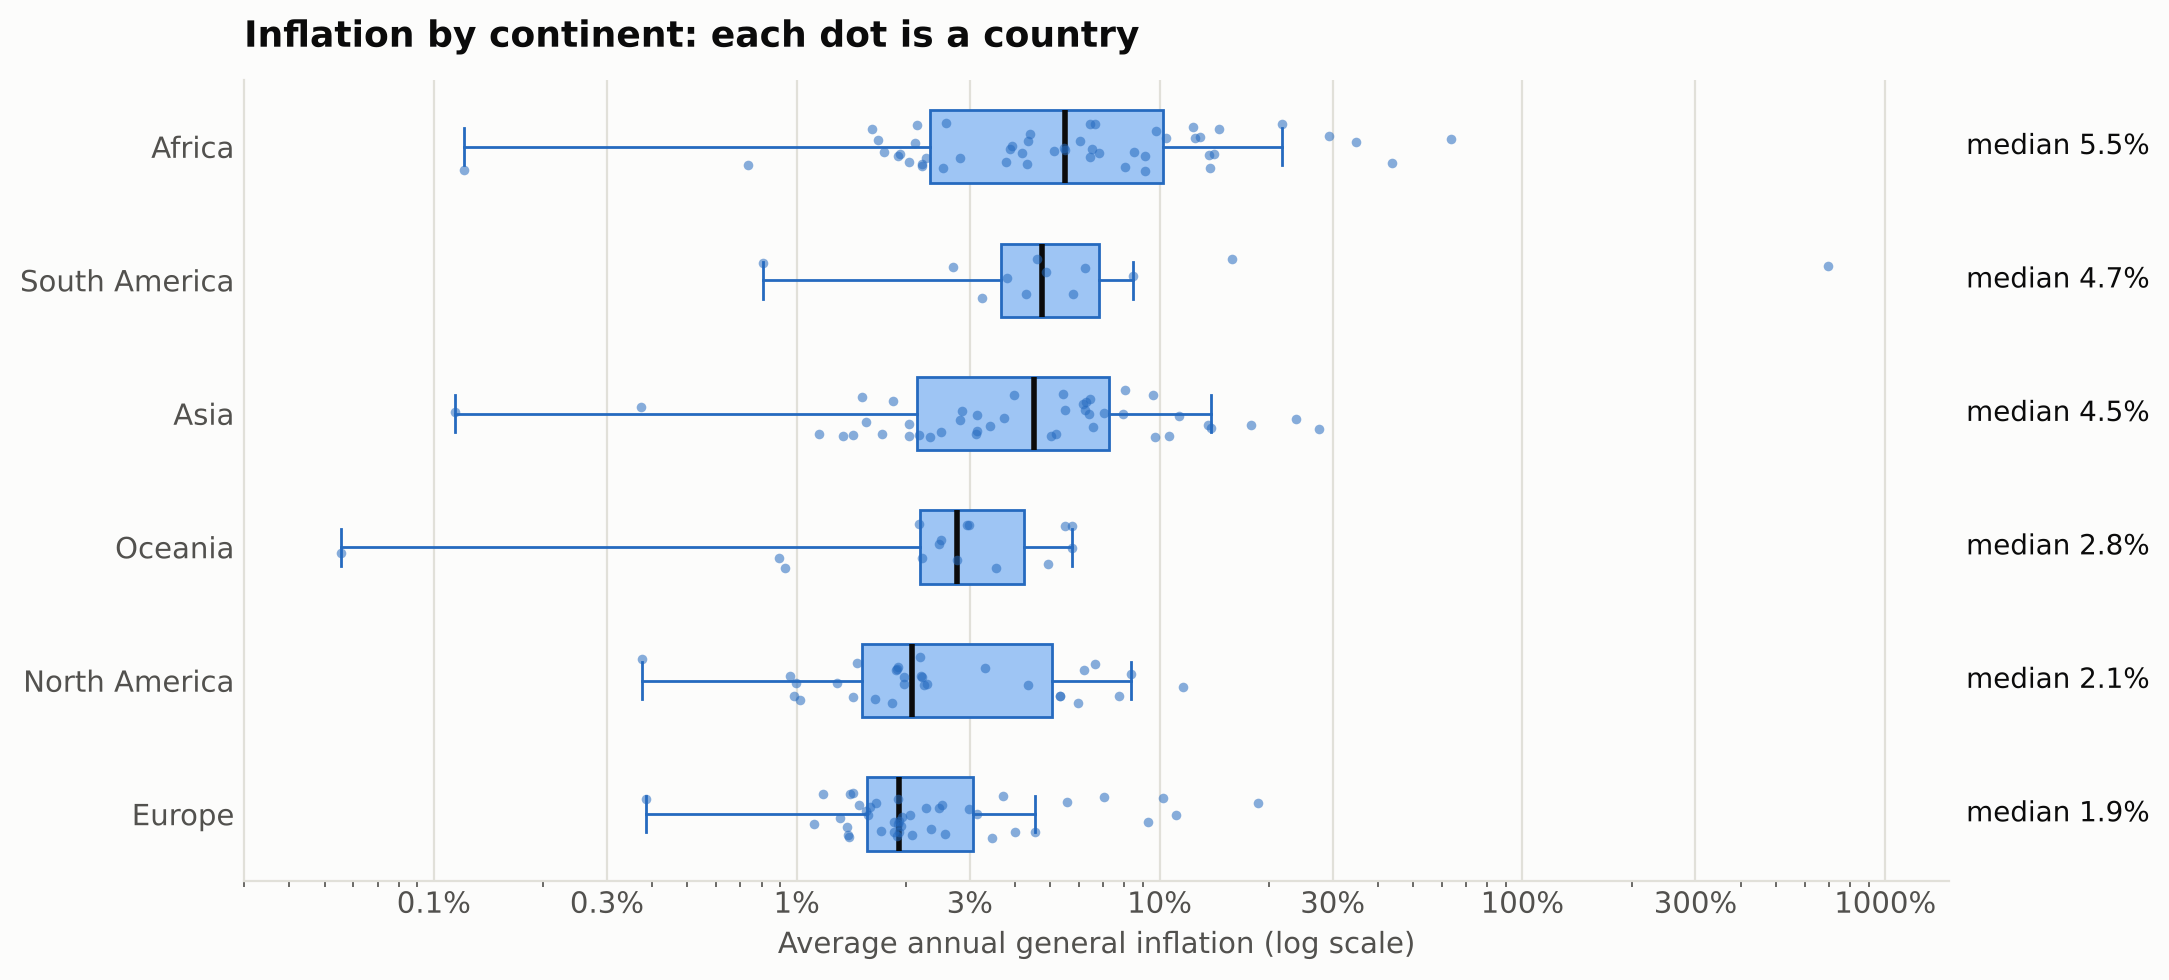

,countries,median % a year,mean % a year
continent,,,
Africa,50,5.47,9.13
South America,12,4.74,62.96
Asia,44,4.50,6.10
Oceania,15,2.77,3.03
North America,30,2.08,3.25
Europe,43,1.92,3.20


In [11]:
order = general.groupby('continent').annual_rate.median().sort_values(ascending=False).index
data = [general.loc[general.continent == c, 'annual_rate'].clip(lower=0.05) for c in order]

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.boxplot(data, orientation='horizontal', widths=0.55, patch_artist=True, showfliers=False,
           medianprops=dict(color=INK, linewidth=2),
           boxprops=dict(facecolor=BLUES[1], edgecolor=BLUES[4], linewidth=1),
           whiskerprops=dict(color=BLUES[4]), capprops=dict(color=BLUES[4]))
rng = np.random.default_rng(0)
for i, d in enumerate(data, start=1):
    ax.scatter(d, i + rng.uniform(-0.18, 0.18, len(d)), s=12, color=BLUES[4], alpha=0.55, zorder=3, linewidths=0)
    ax.annotate(f'median {d.median():.1f}%', (1.01, i), xycoords=('axes fraction', 'data'), va='center', fontsize=10, color=INK)
ax.set_yticks(range(1, len(order) + 1), order)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xticks([0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000], ['0.1%', '0.3%', '1%', '3%', '10%', '30%', '100%', '300%', '1000%'])
ax.set_xlim(0.03, 1500)
ax.grid(axis='x'); ax.set_axisbelow(True)
ax.set_xlabel('Average annual general inflation (log scale)')
ax.set_title('Inflation by continent: each dot is a country', pad=12)
save(fig, 'continents')
plt.show()

display(general.groupby('continent').annual_rate.agg(countries='count', median='median', mean='mean')
        .sort_values('median', ascending=False).rename(columns={'median': 'median % a year', 'mean': 'mean % a year'}))

## 6. Inflation over time

The World Bank's annual inflation series shows how the typical country's inflation moved year by year. Only countries with at least 20 of the 24 years are included, so the mix of countries stays roughly constant.

171 countries with at least 20 years of data


,median,q25,q75,countries,% of countries above 10%
year,,,,,
2007,4.80,2.40,8.00,171,12.90
2008,8.90,5.30,12.40,171,41.50
2009,2.80,0.80,6.40,171,11.70
2019,2.10,0.80,3.70,170,5.90
2020,1.80,0.40,3.70,166,6.00
2021,3.40,1.90,5.60,166,6.00
2022,7.90,5.50,11.60,166,31.30
2023,5.60,3.60,9.10,165,20.60


Highest in 2022: Lebanon 171%, Sudan 139%, Zimbabwe 105%, Argentina 72%, Türkiye 72%
Highest in 2023: Lebanon 221%, Argentina 134%, Türkiye 54%, Suriname 52%, Sierra Leone 48%


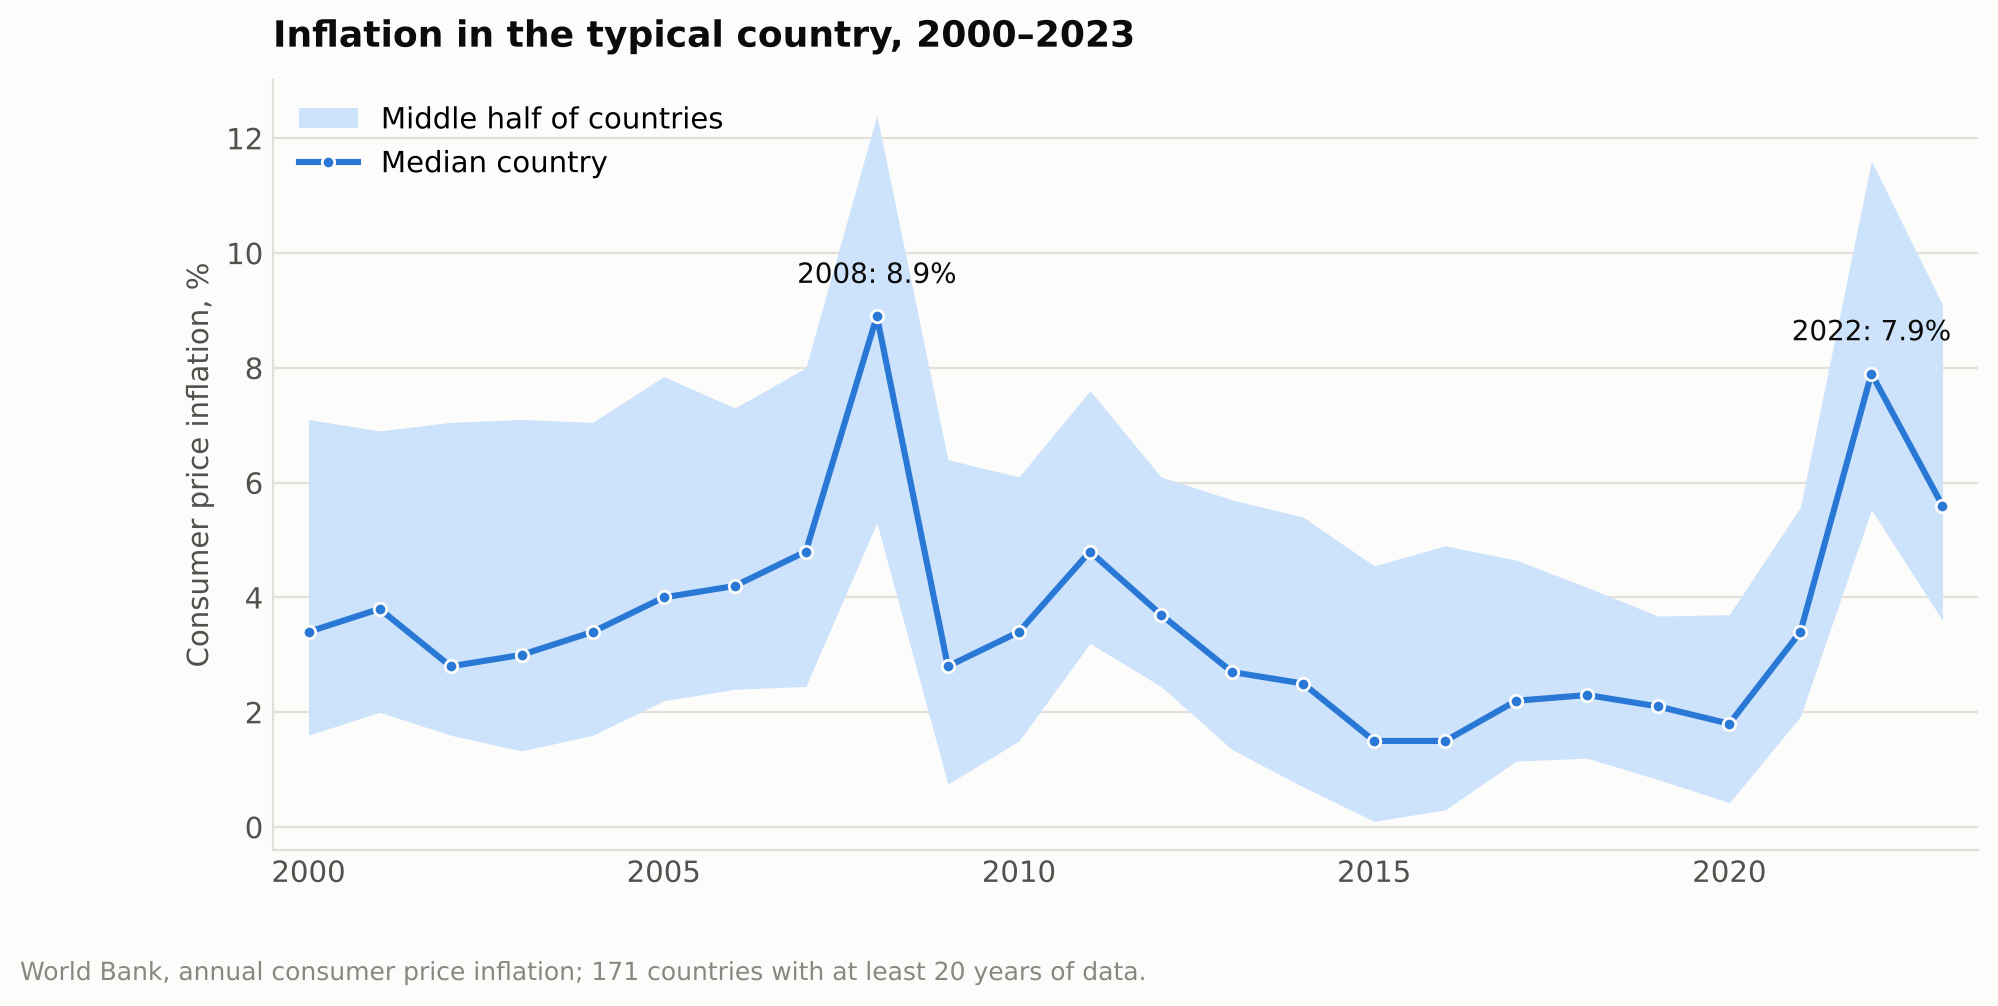

In [12]:
counts = wb.dropna(subset=['inflation']).groupby('iso3').size()
steady = counts[counts >= 20].index
panel = wb[wb.iso3.isin(steady)].dropna(subset=['inflation'])
yearly = panel.groupby('year').inflation.agg(median='median', q25=lambda s: s.quantile(0.25),
                                              q75=lambda s: s.quantile(0.75), countries='count',
                                              over_10=lambda s: (s > 10).mean() * 100)
print(f'{len(steady)} countries with at least 20 years of data')
display(yearly.loc[[2007, 2008, 2009, 2019, 2020, 2021, 2022, 2023]].round(1).rename(
    columns={'over_10': '% of countries above 10%'}))
for yr in [2022, 2023]:
    top5 = wb[wb.year == yr].nlargest(5, 'inflation')
    print(f'Highest in {yr}: ' + ', '.join(f'{short(NAMES.get(i, i))} {v:.0f}%' for i, v in zip(top5.iso3, top5.inflation)))

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(yearly.index, yearly.q25, yearly.q75, color=BLUES[0], linewidth=0, label='Middle half of countries')
ax.plot(yearly.index, yearly['median'], color=SERIES[0], linewidth=2.2, marker='o', markersize=4.5,
        markeredgecolor=SURFACE, label='Median country')
for yr in [2008, 2022]:
    ax.annotate(f'{yr}: {yearly.loc[yr, "median"]:.1f}%', (yr, yearly.loc[yr, 'median']), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=10, color=INK)
ax.set_xlim(1999.5, 2023.5)
ax.set_ylim(bottom=min(0, yearly.q25.min() - 0.5))
ax.set_ylabel('Consumer price inflation, %')
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(loc='upper left')
ax.set_title('Inflation in the typical country, 2000–2023', pad=12)
fig.text(0.01, -0.02, f'World Bank, annual consumer price inflation; {len(steady)} countries with at least 20 years of data.',
         color=MUTED, fontsize=9)
save(fig, 'over-time')
plt.show()

### COVID-19: food first, then everything

The UN data separates food from general prices. Each country's inflation in 2020 and 2021 is compared with its own pre-pandemic pace (the average annual rate from 2015 to 2019).

,2015–19 (per year),2020,2021
Series,,,
General,1.90,1.81,3.52
Food,2.22,3.30,3.11


General: 153 countries; 2021 inflation above their 2015–19 pace in 77%
Food: 103 countries; 2021 inflation above their 2015–19 pace in 56%


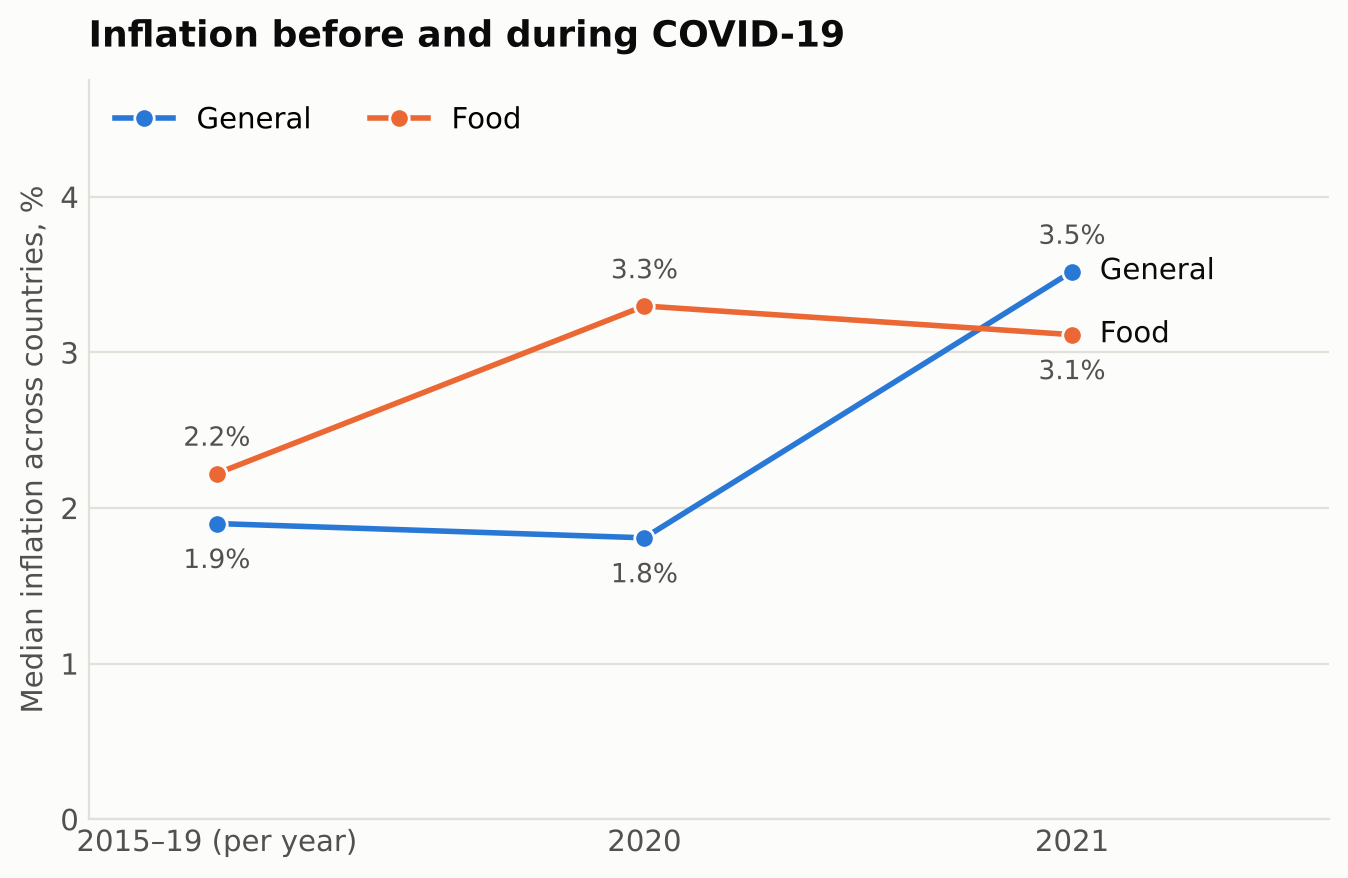

,2015–19 (per year),2020,2021,change (pp)
Country,,,,
Sudan,40.01,163.26,433.96,393.95
Lebanon,3.11,84.92,154.74,151.63
Zimbabwe,40.57,557.17,98.55,57.97
Suriname,20.63,34.91,59.11,38.48
Iran (Islamic Republic of),17.63,30.56,43.36,25.73
Ethiopia,11.69,20.34,26.83,15.14
Kyrgyzstan,1.55,6.29,11.90,10.35
Barbados,3.42,-5.58,12.49,9.07
Seychelles,1.83,1.15,9.81,7.98


In [13]:
windows = {'2015–19 (per year)': (2015, 2019), '2020': (2019, 2020), '2021': (2020, 2021)}
covid = (df.groupby(['Country', 'Series'])
           .apply(lambda d: pd.Series({k: window_rate(d, *v) for k, v in windows.items()}), include_groups=False)
           .dropna())
medians = covid.groupby('Series').median().loc[['General', 'Food']]
display(medians.round(2))
for series in ['General', 'Food']:
    c = covid.xs(series, level='Series')
    print(f"{series}: {len(c)} countries; 2021 inflation above their 2015–19 pace in "
          f"{(c['2021'] > c['2015–19 (per year)']).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(windows))
for i, series in enumerate(['General', 'Food']):
    y = medians.loc[series].values
    other = medians.drop(series).iloc[0].values
    ax.plot(x, y, color=SERIES[i], linewidth=2, marker='o', markersize=7, markeredgecolor=SURFACE, label=series)
    ax.annotate(series, (x[-1], y[-1]), xytext=(10, 0), textcoords='offset points', va='center', color=INK)
    for xi, yi, yo in zip(x, y, other):
        ax.annotate(f'{yi:.1f}%', (xi, yi), xytext=(0, 10 if yi >= yo else -16), textcoords='offset points',
                    ha='center', fontsize=9.5, color=INK_2)
ax.set_xticks(x, list(windows))
ax.set_xlim(-0.3, len(windows) - 0.4)
ax.set_ylim(0, medians.values.max() * 1.35)
ax.set_ylabel('Median inflation across countries, %')
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(loc='upper left', ncol=2)
ax.set_title('Inflation before and during COVID-19', pad=12)
save(fig, 'covid-shock')
plt.show()

jump = covid.xs('General', level='Series')
jump = jump.assign(change=jump['2021'] - jump['2015–19 (per year)']).sort_values('change', ascending=False)
display(jump.head(10).rename(columns={'change': 'change (pp)'}))

## 7. Inflation and the wider economy

Two classic questions, using World Bank data for 2000–2023:

- **Unemployment.** The Phillips curve suggests that when unemployment is low, inflation tends to be higher.
- **Growth.** High inflation is often linked with weaker growth.

Each is checked *across* countries (does a country with higher typical unemployment have lower typical inflation?) and *within* countries (in a given country, do years of lower unemployment come with higher inflation?). Spearman rank correlation is used throughout so that hyperinflation episodes don't dominate. Many unemployment figures for lower-income countries are ILO modelled estimates, so the unemployment results lean more on richer countries' measured data.

In [14]:
typical = wb.groupby('iso3')[['inflation', 'unemployment', 'gdp_growth']].median().dropna()
print(f'{len(typical)} countries with all three indicators')

results = []
for column, label in [('unemployment', 'Unemployment'), ('gdp_growth', 'GDP growth')]:
    rho, p = spearmanr(typical[column], typical.inflation)
    within = []
    for iso, d in wb.dropna(subset=['inflation', column]).groupby('iso3'):
        if len(d) >= 15:
            within.append(spearmanr(d[column], d.inflation)[0])
    within = pd.Series(within).dropna()
    results.append({'indicator': label, 'across countries: ρ': rho, 'p-value': p,
                    'within countries: median ρ': within.median(), 'countries': len(within),
                    'share with negative ρ': (within < 0).mean()})
results = pd.DataFrame(results).set_index('indicator')
display(results.style.format({'across countries: ρ': '{:.2f}', 'p-value': '{:.2g}', 'within countries: median ρ': '{:.2f}',
                              'share with negative ρ': '{:.0%}'}))

177 countries with all three indicators


,across countries: ρ,p-value,within countries: median ρ,countries,share with negative ρ
indicator,,,,,
Unemployment,0.05,0.54,-0.12,172,64%
GDP growth,0.29,9.1e-05,0.07,182,40%


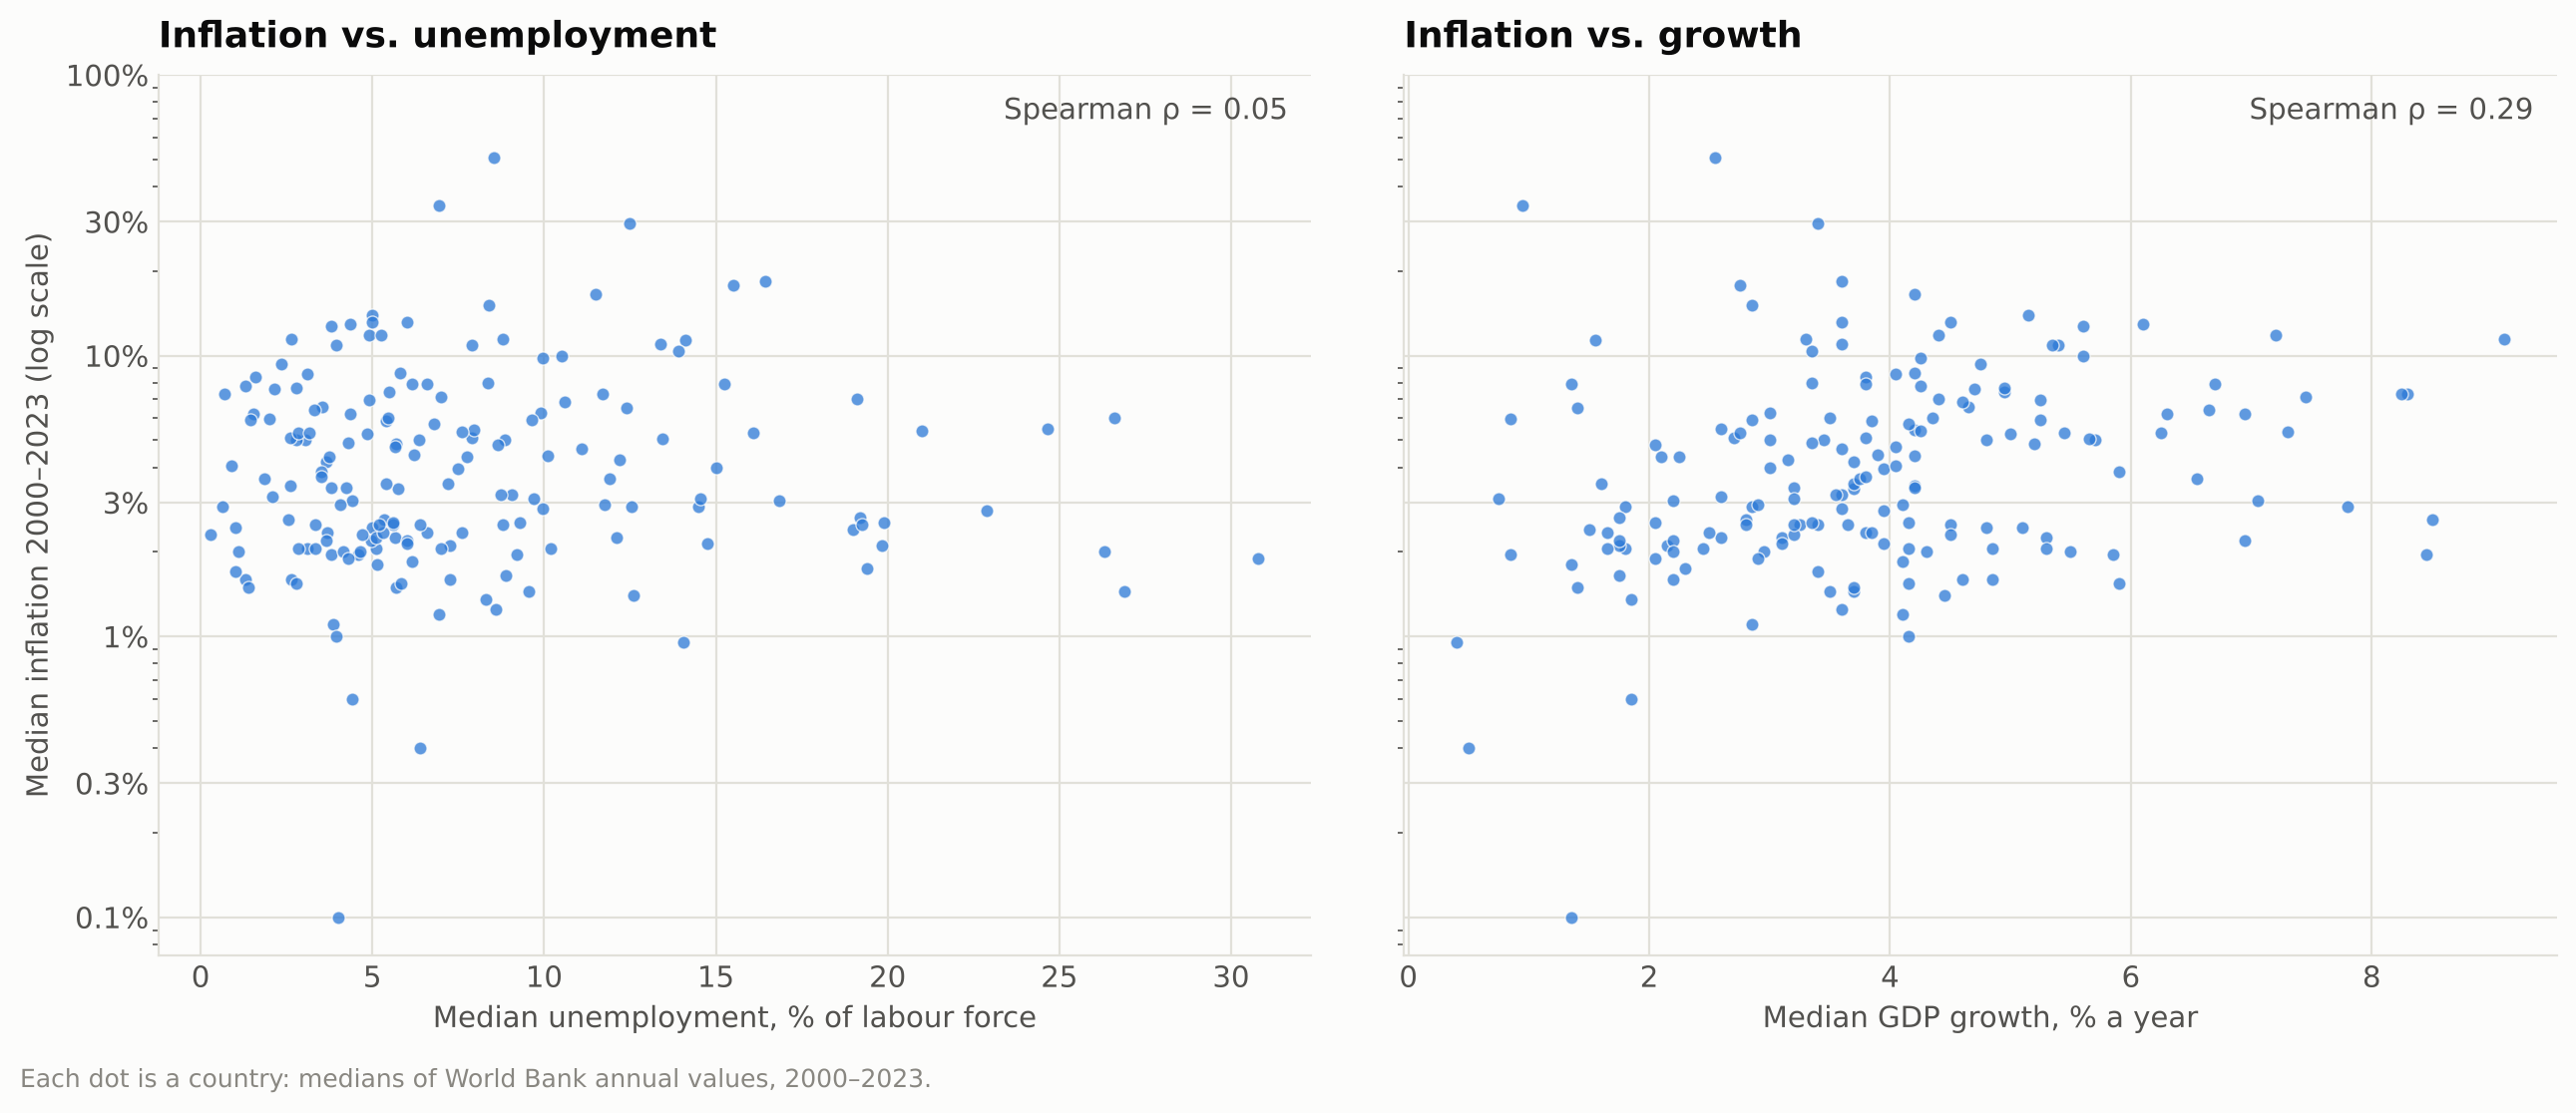

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True)
for ax, column, label in [(axes[0], 'unemployment', 'Median unemployment, % of labour force'),
                          (axes[1], 'gdp_growth', 'Median GDP growth, % a year')]:
    ax.scatter(typical[column], typical.inflation.clip(lower=0.1), s=22, color=SERIES[0], alpha=0.75,
               edgecolors=SURFACE, linewidths=0.5)
    ax.set_yscale('log')
    ax.set_yticks([0.1, 0.3, 1, 3, 10, 30, 100], ['0.1%', '0.3%', '1%', '3%', '10%', '30%', '100%'])
    ax.grid(True); ax.set_axisbelow(True)
    ax.set_xlabel(label)
    rho = results.loc['Unemployment' if column == 'unemployment' else 'GDP growth', 'across countries: ρ']
    ax.text(0.98, 0.95, f'Spearman ρ = {rho:.2f}', transform=ax.transAxes, ha='right', color=INK_2)
axes[0].set_ylabel('Median inflation 2000–2023 (log scale)')
axes[0].set_title('Inflation vs. unemployment', pad=10)
axes[1].set_title('Inflation vs. growth', pad=10)
fig.text(0.01, -0.02, 'Each dot is a country: medians of World Bank annual values, 2000–2023.', color=MUTED, fontsize=9)
fig.tight_layout(w_pad=3)
save(fig, 'economy')
plt.show()

## 8. Countries grouped by their price path

Countries with general CPI on a single base for all of 2005, 2010, 2015, 2019, 2020 and 2021 are grouped by how their prices moved. Each path is rebased to 2010 = 1 and log-transformed, so a 3% rise counts the same at any price level, and the paths are clustered with k-means. The number of groups is chosen by silhouette score, which measures how cleanly the groups separate.

128 countries with a complete path
k=2: silhouette 0.774
k=3: silhouette 0.649
k=4: silhouette 0.606
k=5: silhouette 0.519
k=6: silhouette 0.522
Best separation at k=2


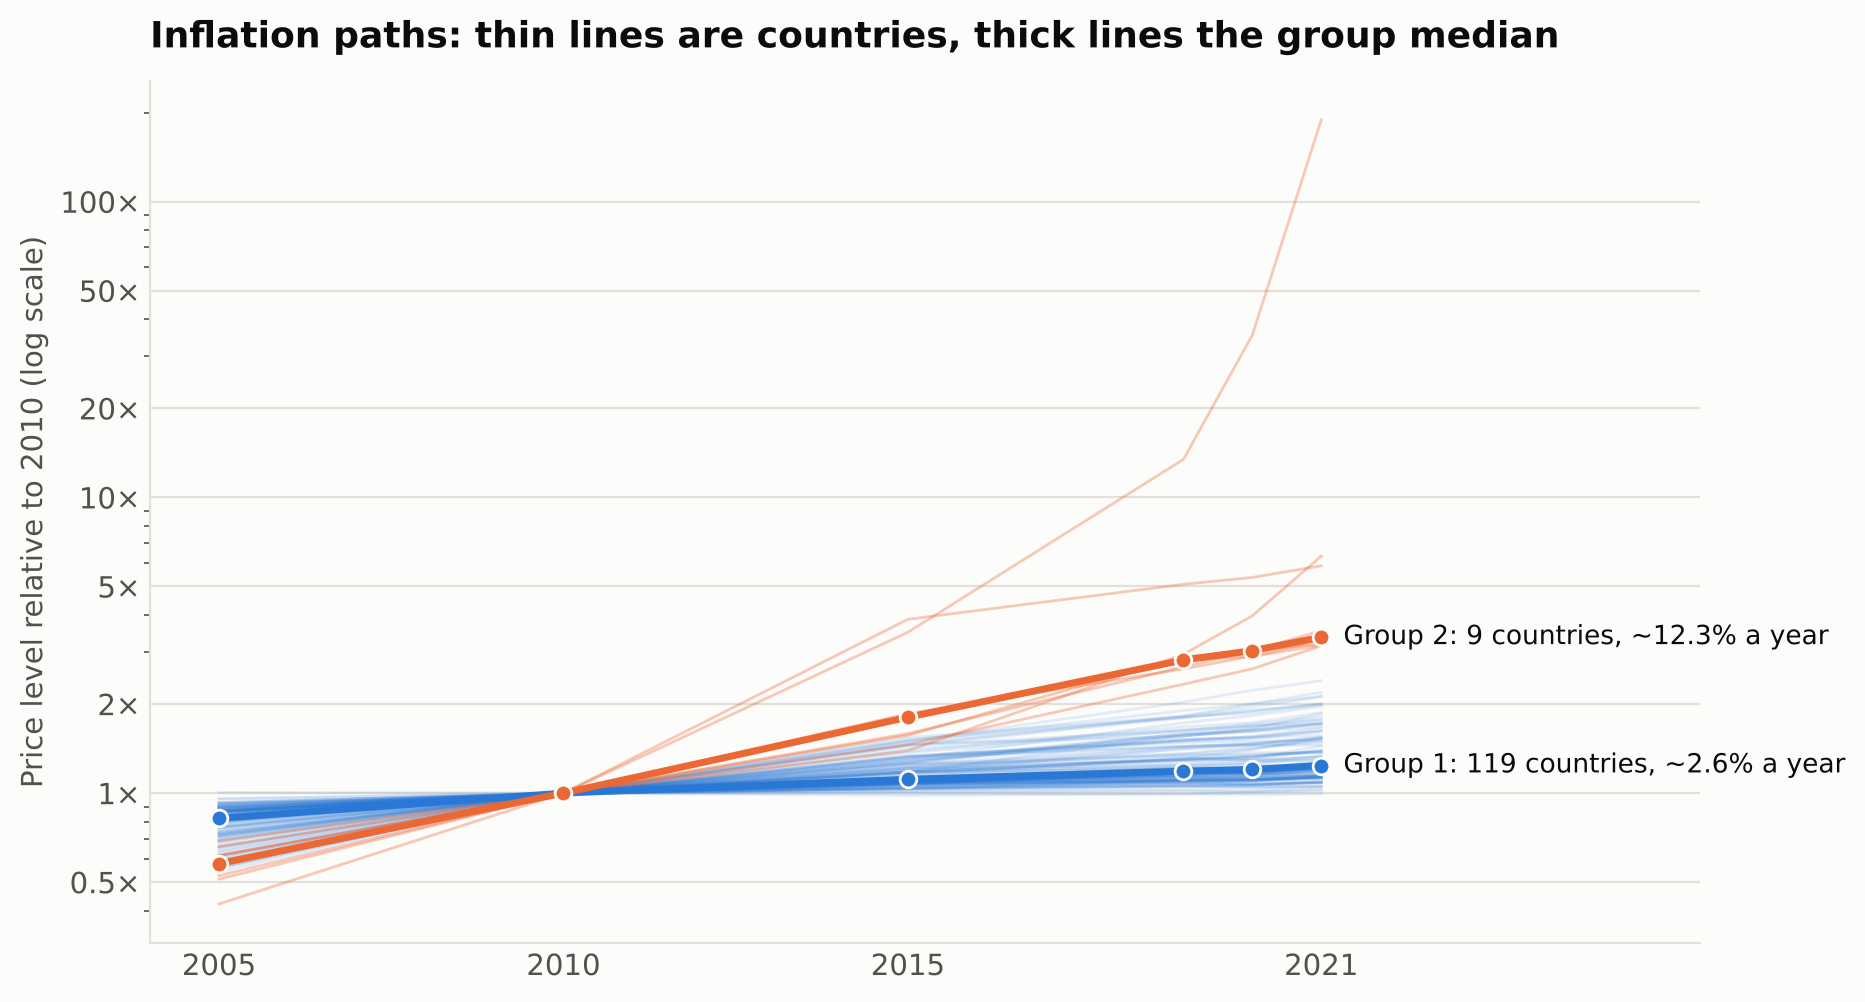

,countries,median % a year,"members (most typical first, or all if few)"
group,,,
Group 1,119,2.57,"Cameroon, Australia, Curaçao, Montenegro, Albania, Vanuatu"
Group 2,9,12.30,"Sudan, Belarus, Suriname, Guinea, Ghana, Ukraine, Nigeria, Egypt, Türkiye"


In [16]:
YEARS = [2005, 2010, 2015, 2019, 2020, 2021]
paths = {}
for country, d in df[df.Series == 'General'].groupby('Country'):
    for _, seg in d.groupby('segment'):
        s = seg.set_index('Year')['Value'].dropna()
        if all(y in s.index for y in YEARS):
            paths[country] = np.log(s.loc[YEARS] / s.loc[2010])
X = pd.DataFrame(paths).T
print(f'{len(X)} countries with a complete path')

scores = {}
for k in range(2, 7):
    scores[k] = silhouette_score(X, KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X))
    print(f'k={k}: silhouette {scores[k]:.3f}')
K = max(scores, key=scores.get)
print(f'Best separation at k={K}')

km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
X['cluster'] = km.labels_
X['rate'] = (np.exp(X[2021] - X[2005]) ** (1 / 16) - 1) * 100
cluster_order = X.groupby('cluster').rate.median().sort_values().index
names = {c: f'Group {i + 1}' for i, c in enumerate(cluster_order)}
X['group'] = X.cluster.map(names)

fig, ax = plt.subplots(figsize=(10, 5.6))
for i, c in enumerate(cluster_order):
    members = X[X.cluster == c]
    for _, row in members.iterrows():
        ax.plot(YEARS, np.exp(row[YEARS].astype(float)), color=SERIES[i], alpha=0.12 if len(members) > 20 else 0.35, linewidth=1)
for i, c in enumerate(cluster_order):
    members = X[X.cluster == c]
    med = np.exp(members[YEARS].astype(float).median())
    ax.plot(YEARS, med, color=SERIES[i], linewidth=2.5, marker='o', markersize=6, markeredgecolor=SURFACE, zorder=5)
    ax.annotate(f'{names[c]}: {len(members)} countries, ~{members.rate.median():.1f}% a year',
                (YEARS[-1], med.iloc[-1]), xytext=(8, 0), textcoords='offset points', va='center', color=INK, fontsize=9.5)
ax.set_yscale('log')
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50, 100], ['0.5×', '1×', '2×', '5×', '10×', '20×', '50×', '100×'])
ax.set_ylabel('Price level relative to 2010 (log scale)')
ax.set_xticks([2005, 2010, 2015, 2021])
ax.set_xlim(2004, 2026.5)
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.set_title('Inflation paths: thin lines are countries, thick lines the group median', pad=12)
save(fig, 'clusters')
plt.show()

def members_list(m, n=6):
    if len(m) <= 12:
        return ', '.join(short(c) for c in m.sort_values('rate', ascending=False).index)
    centre = m[YEARS].astype(float).median()
    dist = ((m[YEARS].astype(float) - centre) ** 2).sum(axis=1)
    return ', '.join(short(c) for c in dist.sort_values().index[:n])

with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame({
        'countries': X.groupby('group').size(),
        'median % a year': X.groupby('group').rate.median(),
        'members (most typical first, or all if few)': X.groupby('group').apply(members_list, include_groups=False),
    }))

## 9. Forecasting

### 9.1 Trend lines on the price index

A simple way to project prices is to draw a trend line through each country's CPI and extend it. The test: fit on 2000–2015, predict 2021, and compare with what happened. Two trend shapes are compared:

- **Linear:** prices rise by the same *amount* every year.
- **Compound (log-linear):** prices rise by the same *percentage* every year, the way inflation usually compounds.

In [17]:
bt = []
for (country, series), d in df.groupby(['Country', 'Series']):
    for _, seg in d.groupby('segment'):
        s = seg.dropna(subset=['Value']).set_index('Year')['Value']
        train = s[s.index <= 2015]
        if len(train) >= 3 and 2021 in s.index:
            Xt = train.index.values.reshape(-1, 1)
            lin = LinearRegression().fit(Xt, train.values).predict([[2021]])[0]
            log = np.exp(LinearRegression().fit(Xt, np.log(train.values)).predict([[2021]])[0])
            actual = s[2021]
            bt.append(dict(Country=country, Series=series, linear=abs(lin - actual) / actual * 100,
                           compound=abs(log - actual) / actual * 100, compound_over=log > actual))
bt = pd.DataFrame(bt)
print(f'{len(bt)} country series with at least 3 points up to 2015 and a 2021 value on the same base')
display(bt.groupby('Series')[['linear', 'compound']].median().rename(
    columns={'linear': 'linear: median % error', 'compound': 'compound: median % error'}))
print(f"Compound closer in {(bt.compound < bt.linear).mean():.0%} of cases; "
      f"it over-predicts 2021 prices in {bt.compound_over.mean():.0%}")

pace = pd.DataFrame({
    '2000–10': df[df.Series == 'General'].groupby('Country').apply(lambda d: window_rate(d, 2000, 2010), include_groups=False),
    '2010–19': df[df.Series == 'General'].groupby('Country').apply(lambda d: window_rate(d, 2010, 2019), include_groups=False),
}).dropna()
print(f"Median general inflation {pace['2000–10'].median():.1f}% a year in 2000–10 vs {pace['2010–19'].median():.1f}% "
      f"in 2010–19; slower in the 2010s for {(pace['2010–19'] < pace['2000–10']).mean():.0%} of {len(pace)} countries")

# Projection to 2030 with the better-performing linear trend, fitted on each country's longest same-base segment
rising = {}
for series in ['General', 'Food']:
    up = n = 0
    for _, d in df[df.Series == series].groupby('Country'):
        seg = max((g.dropna(subset=['Value']) for _, g in d.groupby('segment')), key=len)
        if len(seg) >= 3:
            m = LinearRegression().fit(seg[['Year']].values, seg.Value.values)
            n += 1
            up += m.predict([[2030]])[0] > seg.Value.iloc[-1]
    rising[series] = (up, n)
    print(f'{series}: prices projected higher in 2030 than their latest value in {up} of {n} countries')

180 country series with at least 3 points up to 2015 and a 2021 value on the same base


,linear: median % error,compound: median % error
Series,,
Food,4.79,9.26
General,6.57,11.33


Compound closer in 23% of cases; it over-predicts 2021 prices in 89%


Median general inflation 3.6% a year in 2000–10 vs 2.2% in 2010–19; slower in the 2010s for 85% of 138 countries


General: prices projected higher in 2030 than their latest value in 193 of 197 countries


Food: prices projected higher in 2030 than their latest value in 134 of 137 countries


### 9.2 Year-ahead inflation forecasts

With the World Bank's yearly figures, three simple forecasting methods are compared on each country's inflation rate:

- **Last value:** next year's inflation equals this year's.
- **5-year average:** the mean of the last five years.
- **AR(1):** a first-order autoregressive model (ARIMA(1,0,0)) fitted to the country's history.

Each predicts four years ahead in two tests: a calm period (train to 2015, predict 2016–2019) and a shock (train to 2019, predict 2020–2023). The score is the mean absolute error in percentage points, summarised by the median across countries.

Countries per test: {'Calm: 2016–2019': 160, 'Shock: 2020–2023': 153}


test,Calm: 2016–2019,Shock: 2020–2023
model,,
Last value,1.55,3.15
5-year average,1.46,3.13
AR(1),1.70,2.72


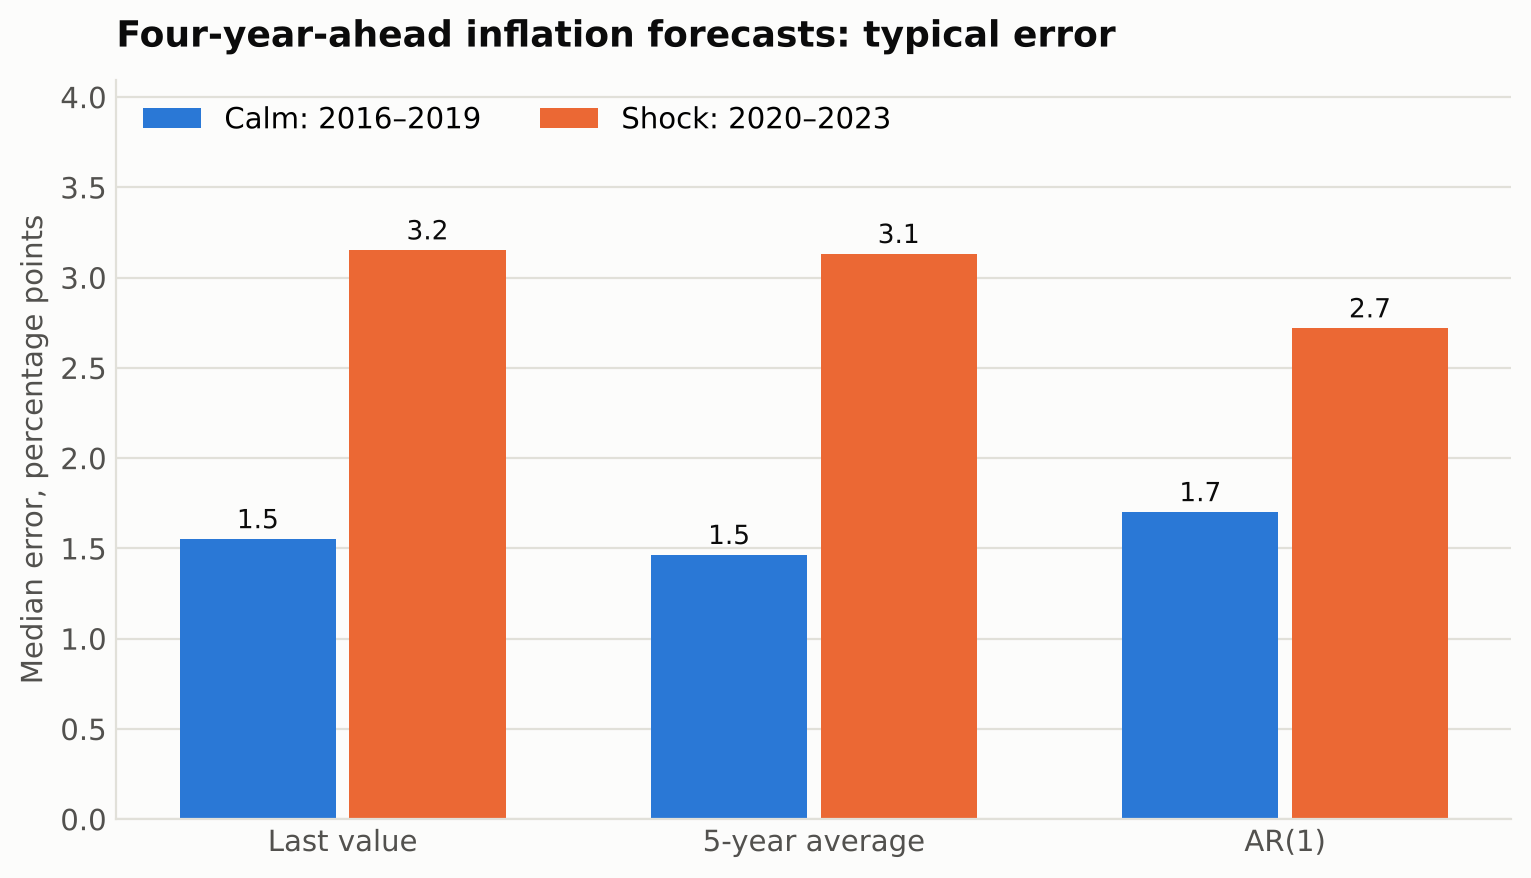

In [18]:
def forecasts(train, horizon):
    ar = ARIMA(train.values, order=(1, 0, 0)).fit().forecast(horizon)
    return {'Last value': np.repeat(train.iloc[-1], horizon),
            '5-year average': np.repeat(train.iloc[-5:].mean(), horizon),
            'AR(1)': ar}

tests = {'Calm: 2016–2019': (2015, [2016, 2017, 2018, 2019]), 'Shock: 2020–2023': (2019, [2020, 2021, 2022, 2023])}
infl = wb.pivot_table(index='iso3', columns='year', values='inflation')
scores = []
for test, (last, years) in tests.items():
    for iso, row in infl.iterrows():
        train = row.loc[2000:last]
        if train.notna().all() and row.loc[years].notna().all():
            for model, pred in forecasts(train, len(years)).items():
                scores.append(dict(test=test, iso3=iso, model=model, mae=np.mean(np.abs(pred - row.loc[years].values))))
scores = pd.DataFrame(scores)
summary = scores.pivot_table(index='model', columns='test', values='mae', aggfunc='median').loc[['Last value', '5-year average', 'AR(1)']]
print('Countries per test:', scores.groupby('test').iso3.nunique().to_dict())
display(summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(summary))
w = 0.36
for i, test in enumerate(tests):
    vals = summary[test].values
    ax.bar(x + (i - 0.5) * w, vals, width=w * 0.92, color=SERIES[i], label=test)
    for xi, v in zip(x + (i - 0.5) * w, vals):
        ax.annotate(f'{v:.1f}', (xi, v), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9.5, color=INK)
ax.set_xticks(x, summary.index)
ax.set_ylim(0, summary.values.max() * 1.3)
ax.set_ylabel('Median error, percentage points')
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(loc='upper left', ncol=2)
ax.set_title('Four-year-ahead inflation forecasts: typical error', pad=12)
save(fig, 'forecasts')
plt.show()

## 10. Pakistan and Southern Asia

Pakistan's inflation compared with its UN-defined region, Southern Asia, using the World Bank's yearly figures.

Southern Asia: Afghanistan, Bangladesh, Bhutan, India, Iran, Sri Lanka, Maldives, Nepal, Pakistan


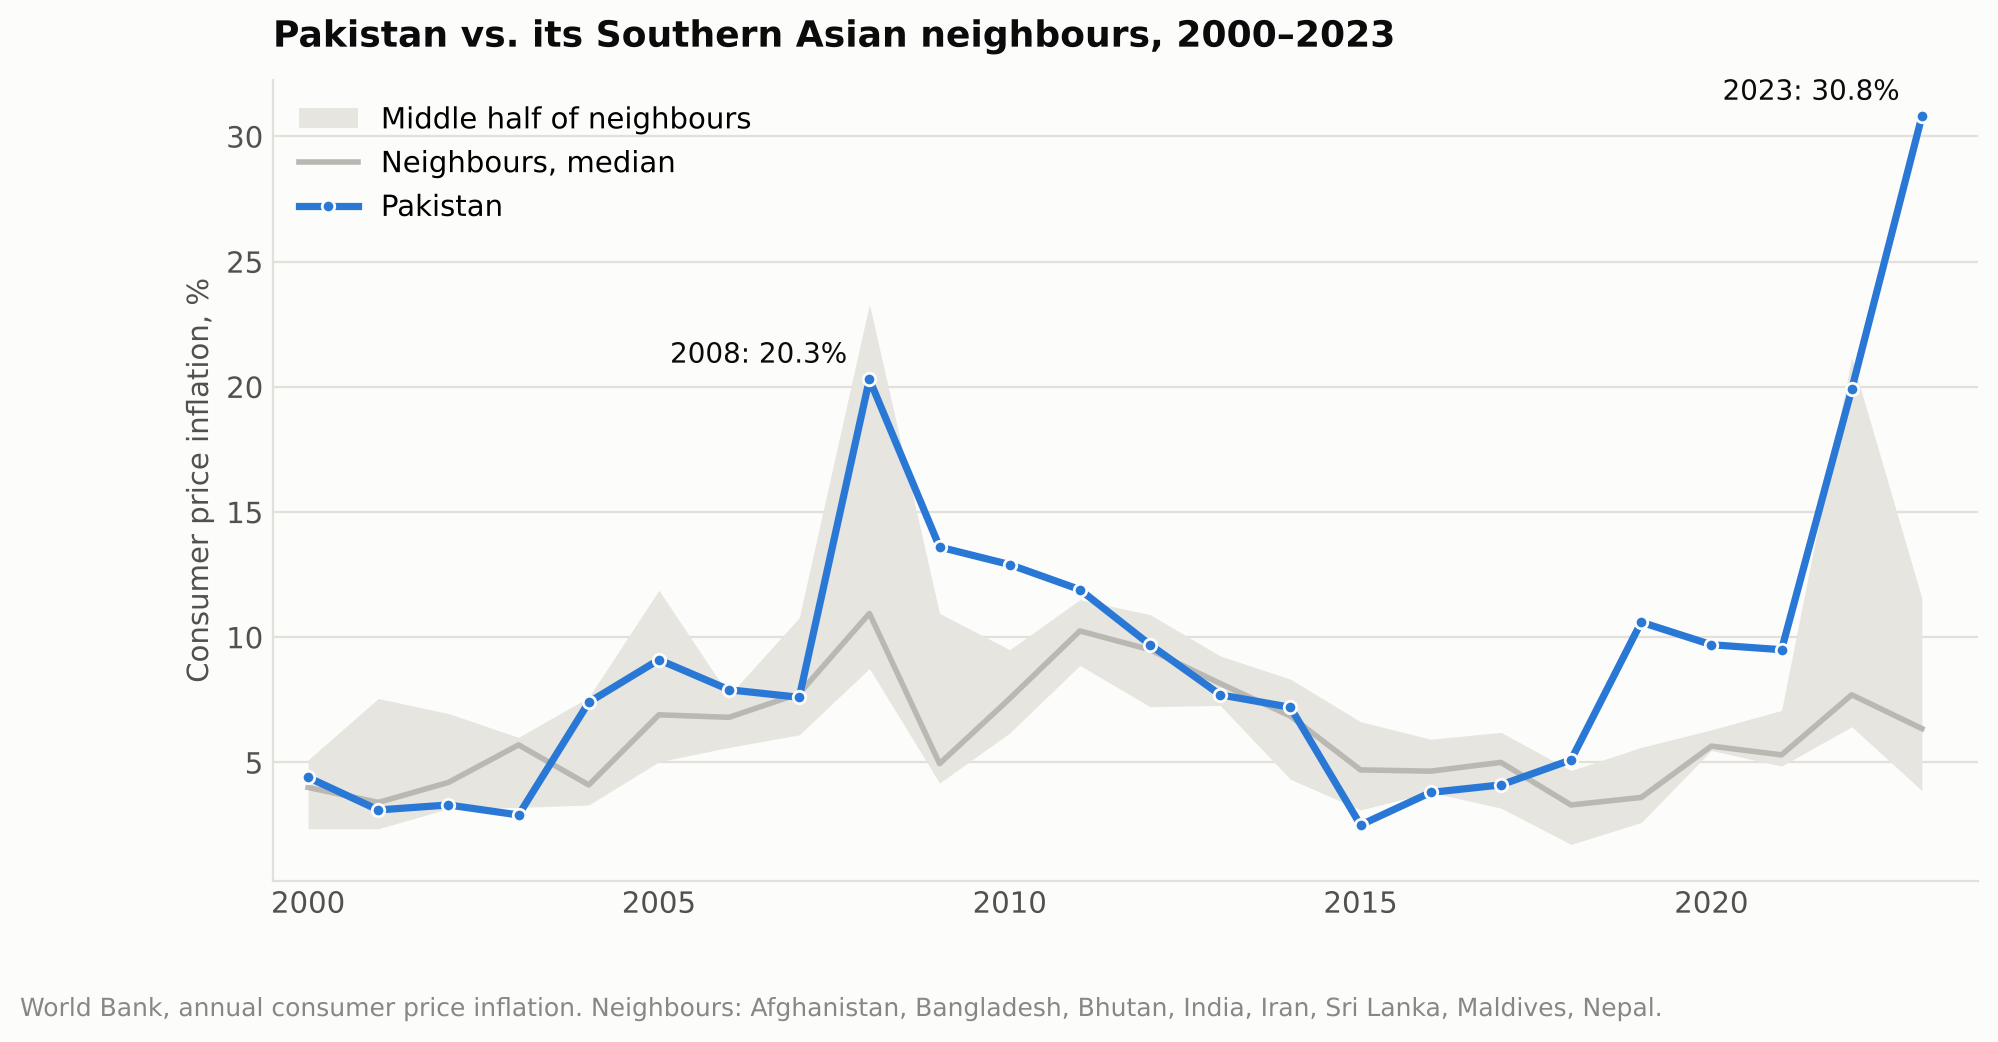

,Pakistan,Neighbours (median)
"Median year, 2000–2023",7.80,5.80
"Average, 2015–2019",5.20,4.20
"Average, 2019–2023",16.10,5.70
2022,19.90,7.70
2023,30.80,6.40


Pakistan above the neighbours' median in 16 of 24 years
Pakistan's price level in 2023: 7.9 times its 2000 level


year,2008,2015,2021,2022,2023
Iran,25.40,12.50,43.40,43.50,44.60
Pakistan,20.30,2.50,9.50,19.90,30.80
Sri Lanka,22.60,3.80,7.00,49.70,16.50
Bangladesh,8.90,6.20,5.50,7.70,9.90
Nepal,9.90,7.90,4.10,7.70,7.10
India,8.30,4.90,5.10,6.70,5.60
Bhutan,8.30,4.50,7.30,5.60,4.20
Maldives,12.00,1.00,0.50,2.30,2.90
Afghanistan,26.40,-0.70,5.10,13.70,-4.60


Pakistan, UN general CPI: 8.0% a year (2000–2021)


In [19]:
SOUTH_ASIA = meta[meta.un_subregion == 'Southern Asia'].index.tolist()
sa = infl.loc[infl.index.intersection(SOUTH_ASIA), 2000:2023]
peers = sa.drop('PAK')
print('Southern Asia:', ', '.join(short(NAMES[i]) for i in sa.index))

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.fill_between(peers.columns, peers.quantile(0.25), peers.quantile(0.75), color='#e6e5e0', linewidth=0,
                label='Middle half of neighbours')
ax.plot(peers.columns, peers.median(), color=NEUTRAL, linewidth=2, label='Neighbours, median')
ax.plot(sa.columns, sa.loc['PAK'], color=SERIES[0], linewidth=2.6, marker='o', markersize=4.5, markeredgecolor=SURFACE,
        label='Pakistan')
for yr in [2008, 2023]:
    ax.annotate(f'{yr}: {sa.loc["PAK", yr]:.1f}%', (yr, sa.loc['PAK', yr]), xytext=(-8, 6), textcoords='offset points',
                ha='right', fontsize=10, color=INK)
ax.set_xlim(1999.5, 2023.8)
ax.set_ylabel('Consumer price inflation, %')
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(loc='upper left')
ax.set_title('Pakistan vs. its Southern Asian neighbours, 2000–2023', pad=12)
fig.text(0.01, -0.02, 'World Bank, annual consumer price inflation. Neighbours: ' +
         ', '.join(short(NAMES[i]) for i in peers.index) + '.', color=MUTED, fontsize=9)
save(fig, 'pakistan')
plt.show()

pak = wb[wb.iso3 == 'PAK'].set_index('year')
summary_pk = pd.DataFrame({
    'Pakistan': [pak.loc[2000:2023, 'inflation'].median(), pak.loc[2015:2019, 'inflation'].mean(),
                 pak.loc[2019:2023, 'inflation'].mean(), pak.loc[2022, 'inflation'], pak.loc[2023, 'inflation']],
    'Neighbours (median)': [peers.loc[:, 2000:2023].median(axis=1).median(), peers.loc[:, 2015:2019].mean(axis=1).median(),
                            peers.loc[:, 2019:2023].mean(axis=1).median(), peers[2022].median(), peers[2023].median()],
}, index=['Median year, 2000–2023', 'Average, 2015–2019', 'Average, 2019–2023', '2022', '2023'])
display(summary_pk.round(1))
print(f"Pakistan above the neighbours' median in {(sa.loc['PAK'] > peers.median()).sum()} of {sa.loc['PAK'].notna().sum()} years")
print(f"Pakistan's price level in 2023: {(1 + sa.loc['PAK', 2001:2023] / 100).prod():.1f} times its 2000 level")
display(sa[[2008, 2015, 2021, 2022, 2023]].rename(index=lambda i: short(NAMES[i])).rename_axis(None).sort_values(2023, ascending=False).round(1))
print(f"Pakistan, UN general CPI: {general.loc['Pakistan', 'annual_rate']:.1f}% a year "
      f"({int(general.loc['Pakistan', 'start'])}–{int(general.loc['Pakistan', 'end'])})")

## Findings

A written summary of the results, with the charts, is in [`FINDINGS.md`](FINDINGS.md).